# 1. Portada académica

# Evaluación comparativa de algoritmos de regresión supervisada para la predicción de la carga de primera falla en estructuras pantográficas mediante características geométricas experimentales

**Universidad Nacional de Ingeniería**  
Maestría en Inteligencia Artificial · Trabajo de Investigación II  
**Investigadora** Melissa Dessire Aylas Barranca  
**Docente** Glen Dario Rodríguez Rafael  
Rama **benchmark-regresion-6-modelos** · Noviembre de 2026

La unidad de análisis es un espécimen. Cada predicción evaluada se obtiene reservando su configuración nominal o su nivel celular completo. El error se expresa en newtons.

## 2. Introducción y objetivo

La comparación responde a la revisión docente de la elección de los algoritmos. Primero se pregunta cuánto error cometen seis regresores conocidos bajo la misma geometría y las mismas particiones. Después se evalúa si ajustar dos familias escogidas **dentro de cada entrenamiento** aporta una mejora que compense el costo y la complejidad. La fuente disponible documenta el cuestionamiento general de la selección, sin atribuir al docente rechazos individuales.

In [1]:
from pathlib import Path
import hashlib
import html
import json
import platform
import sys

import numpy as np
import pandas as pd
from IPython.display import HTML, Image, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "config/benchmark_regresion.json").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.figuras_benchmark_regresion import MODELOS, NOMBRES, PROTO, PROTOCOLOS, generar_figuras, leer_resultados
from src.antecedentes_benchmark import build as reconstruir_antecedentes

CFG = json.loads((ROOT / "config/benchmark_regresion.json").read_text(encoding="utf-8"))
LECTURA = json.loads((ROOT / "config/lectura_benchmark_regresion.json").read_text(encoding="utf-8"))
BASE = ROOT / "reports/benchmark_regresion"
TABLAS = BASE / "tables"
if not all((ROOT / "docs/benchmark" / f).exists() for f in ["antecedentes_metricas.csv", "features.csv"]):
    reconstruir_antecedentes(ROOT)
muestras = pd.read_csv(ROOT / "data/processed/preliminary/model_table.csv")
features = pd.read_csv(ROOT / "docs/benchmark/features.csv")
historia = pd.read_csv(ROOT / "docs/benchmark/antecedentes_metricas.csv")
particiones = pd.read_csv(ROOT / "reports/permutation_importance/tables/particiones_externas.csv")
target = CFG["target"]
grupo_cols = ["n_cells_Y", "Fiber_height", "Pivot_height"]

def fmt(x, posiciones=2):
    return f"{float(x):.{posiciones}f}".replace(".", ",")

def nombre(codigo):
    return NOMBRES.get(codigo, str(codigo))

def tabla(frame):
    estilo = """<style>.tabla-benchmark table{border-collapse:collapse;font-size:13px;color:#213b40;background:white}
    .tabla-benchmark th,.tabla-benchmark td{padding:5px 8px;border-bottom:1px solid #dce6e0;text-align:left;vertical-align:top}
    .tabla-benchmark th{background:#f2f6f3;font-weight:600}.tabla-benchmark td{max-width:34em;overflow-wrap:anywhere}</style>"""
    contenido = frame.to_html(index=False, border=0, na_rep="—", float_format=lambda x: fmt(x, 3), escape=True)
    display(HTML(estilo + '<div class="tabla-benchmark" style="background:white;overflow-x:auto;max-width:100%">' + contenido + '</div>'))

def ficha_corta(m):
    p = CFG["parametros_iniciales"].get(m, {})
    if m == "SVR_RBF": return f"RBF, C={p['C']:g}, ε={p['epsilon']:g} N, γ={p['gamma']}"
    if m == "XGBoost": return f"{p['n_estimators']} árboles, profundidad {p['max_depth']}, η={p['learning_rate']}"
    if m == "CatBoost": return f"{p['iterations']} iteraciones, profundidad {p['depth']}, η={p['learning_rate']}"
    if m == "KNN": return f"k={p['n_neighbors']}, p={p['p']}, pesos {p['weights']}"
    if m == "Arbol_decision": return f"Profundidad {p['max_depth']}, hoja mínima {p['min_samples_leaf']}"
    if m == "Lineal_multiple": return "Mínimos cuadrados con intercepto y base de rango completo"
    if m == "Ridge_historico": return f"α={p['alpha']:g}, solucionador {p['solver']}"
    if m == "Media_por_nivel": return "Media por Y, con media de entrenamiento para nivel ausente"
    if m == "Dummy_mediana": return "Mediana del entrenamiento"
    return "Familia y parámetros elegidos dentro del entrenamiento"

def caja(resultado, estadistica, mecanica, limitacion, decision):
    campos = [("Resultado verificado", resultado), ("Interpretación estadística", estadistica),
              ("Interpretación mecánica plausible", mecanica), ("Limitación", limitacion), ("Decisión", decision)]
    filas = ''.join(f'<p style="margin:0.34em 0"><strong>{k}</strong> · {html.escape(str(v))}</p>' for k, v in campos)
    display(HTML('<div style="background:#E8F5E9;border-left:5px solid #2E7D32;color:#1B4332;'
                 'padding:12px 16px;margin:12px 0;line-height:1.48">' + filas + '</div>'))

def figura(n):
    display(Image(filename=str(figuras[n - 1]), width=1000))

def codigos(series):
    return ", ".join(nombre(m) for m in series) or "ninguno"

caja(f"Se comparan {len(CFG['familias'])} regresores y {len(CFG['referencias'])} referencias en {len(PROTOCOLOS)} protocolos.",
     "El MAE de predicciones externas es la medida principal. El protocolo por nivel celular evalúa otra pregunta.",
     "Cambiar el número de celdas también cambia dimensiones y conexiones de la arquitectura.",
     "Una única campaña limita la transferencia a otros procesos de fabricación y condiciones de carga.",
     "Mantener separados los resultados por configuración y por nivel celular.")

## 3. Definición del problema predictivo

**First_Failure_Load_N** es la carga reportada en la primera falla [N]. Para predecirla se admiten las dimensiones y conteos geométricos disponibles antes del ensayo. El identificador sirve para las uniones y comprobaciones. Las energías, las fuerzas posteriores, el desplazamiento máximo, los residuales cíclicos y las medidas de daño requieren haber realizado el ensayo.

In [2]:
predictores = features["Feature"].tolist()
assert target == "First_Failure_Load_N" and CFG["unidad"] == "N"
assert len(predictores) == len(set(predictores)) and set(predictores).issubset(muestras)
assert not set(predictores).intersection({target, "Case_n", "__source_record", "Ultimate_Load", "Maximum_Displacement"})
assert muestras.Case_n.is_unique and muestras[target].notna().all()
resumen_y = muestras.groupby("n_cells_Y")[target].agg(["count", "mean", "median", "min", "max"]).reset_index()
tabla(resumen_y.rename(columns={"n_cells_Y":"Celdas Y", "count":"Especímenes", "mean":"Media [N]", "median":"Mediana [N]", "min":"Mínimo [N]", "max":"Máximo [N]"}))
caja(f"El target de {len(muestras)} especímenes varía entre {fmt(muestras[target].min())} y {fmt(muestras[target].max())} N.",
     f"Las medias descriptivas por nivel celular abarcan {fmt(resumen_y['mean'].min())} a {fmt(resumen_y['mean'].max())} N.",
     "La arquitectura puede modificar las trayectorias de carga que preceden al primer daño.",
     "Cada espécimen tiene una respuesta escalar. El instante y el mecanismo local de la rotura requieren registros adicionales.",
     "Usar una fila por respuesta observada y conservar el caso sin ensayo fuera de las métricas.")

Celdas Y,Especímenes,Media [N],Mediana [N],Mínimo [N],Máximo [N]
"4,000",8,"68,984","67,120","47,550","88,500"
"5,000",9,"99,379","100,770","75,710","114,300"
"6,000",9,"203,644","205,340","191,390","215,520"


## 4. Antecedentes y baseline histórico

El inventario recupera los experimentos de ingeniería de características, la comparación fija previa, el ajuste anidado y los análisis de importancia. Ridge con representación A y la media de entrenamiento por nivel celular son comparadores recuperables bajo los mismos pliegues. SVR con núcleo RBF ya se evaluó y su inclusión obligatoria permite comprobar continuidad. Los demás algoritmos históricos quedan identificados por etapa. Las cuatro entradas prioritarias del sprint anterior podían cambiar por modelo y entrenamiento.

In [3]:
inventario = historia.groupby("etapa",sort=False).agg(procedimientos=("procedimiento","nunique"), protocolos=("protocolo","nunique"), modelos=("modelo",lambda s:", ".join(pd.unique(s.astype(str))))).reset_index()
tabla(inventario)
previo = pd.read_csv(ROOT / "reports/permutation_importance/tables/metricas_resumen.csv")
antecedentes = previo[((previo.modelo.isin(["Ridge","SVR_RBF"])) & (previo.conjunto=="todas")) | (previo.modelo=="Media_por_nivel")]
tabla(antecedentes[["protocolo","modelo","conjunto","MAE_N","RMSE_N","R2"]])
h1 = antecedentes.set_index(["protocolo","modelo"])
caja(f"Ridge histórico obtuvo MAE {fmt(h1.loc[('configuracion','Ridge'),'MAE_N'])} N al reservar configuraciones y {fmt(h1.loc[('familia','Ridge'),'MAE_N'])} N al reservar niveles.",
     "La referencia por nivel distingue el beneficio de explotar una arquitectura conocida. Cuando falta el nivel usa la media global del entrenamiento.",
     "Familias con igual número de celdas pueden compartir escala geométrica y rangos de primera falla.",
     "El historial estudió esta misma campaña. El rendimiento entre experimentos con otras entradas exige leer sus protocolos.",
     "Recalcular los controles en las mismas reservas del nuevo benchmark y conservar la tabla de antecedentes separada.")

etapa,procedimientos,protocolos,modelos
04 · variantes,5,2,"Media de entrenamiento, Ridge(alpha=1, solver=svd)"
04 · familias fijas,5,2,"Ridge, ElasticNet, SVR_RBF, RandomForest, GaussianProcess"
05 · ajuste anidado,9,2,"Baseline_Ridge, Ridge, ElasticNet, SVR_RBF, RandomForest, ExtraTrees, GaussianProcess, GradientBoosting, Selector_interno"
06 · importancia anterior,9,2,"Dummy, Ridge, ElasticNet"
06 · permutación,3,2,"Ridge, ElasticNet, SVR_RBF, RandomForest, GaussianProcess, Mediana, Media_por_nivel"


protocolo,modelo,conjunto,MAE_N,RMSE_N,R2
configuracion,Ridge,todas,"13,247","16,346","0,923"
configuracion,SVR_RBF,todas,"15,651","19,096","0,894"
configuracion,Media_por_nivel,referencia,"10,126","12,308","0,956"
familia,Ridge,todas,"57,637","60,428","-0,058"
familia,SVR_RBF,todas,"82,358","88,039","-1,246"
familia,Media_por_nivel,referencia,"80,593","87,521","-1,219"


## 5. Justificación bibliográfica de los seis modelos

Xu, Ji, Li y Lu describen las dificultades de aprender relaciones estables con pocos materiales y observaciones. La revisión motiva controles sencillos y evaluación fuera de muestra. [Xu et al., 2023](https://doi.org/10.1038/s41524-023-01000-z)

En retículas impresas, Huang et al. compararon SVR, XGBoost y CatBoost usando parámetros del proceso. Zhang et al. relacionaron XGBoost con la tensión máxima calculada para retículas BCC con defectos. Aquí cambian la arquitectura, los predictores y la respuesta experimental. [Huang et al., 2026](https://doi.org/10.1007/s40964-025-01409-6) · [Zhang et al., 2023](https://doi.org/10.1007/s40747-023-01061-z)

Nenchev et al. estudiaron la templabilidad de aceros y Megahed contrastó los tres modelos del grupo A para cortante de vigas de hormigón armado. Estos trabajos aportan precedentes de uso en propiedades mecánicas de otros materiales. La elección y el desempeño para pantográficas se juzgan con los resultados de esta campaña. [Nenchev et al., 2022](https://doi.org/10.1007/s12613-022-2437-0) · [Megahed, 2024](https://doi.org/10.1038/s41598-024-64386-w)

| Modelo | Fundamento e hipótesis que contrasta | Riesgo para esta campaña |
|---|---|---|
| SVR RBF · A | El núcleo relaciona configuraciones cercanas. C penaliza errores fuera del tubo de tolerancia ε [N] y γ controla el alcance de esa similitud. Los vectores de soporte determinan la predicción. | Pocas geometrías condicionan el ajuste. Cambiar de escala altera las distancias. |
| XGBoost · A | Añade árboles que corrigen errores sucesivos. Profundidad, tasa de aprendizaje y regularización limitan las reglas e interacciones. | Pocos puntos pueden sostener una partición particular. |
| CatBoost · A | Suma árboles simétricos de poca profundidad y regulariza sus hojas. Esa geometría de partición difiere de la de XGBoost. | Todas las entradas son numéricas. La capacidad de tratar categorías no aporta aquí una ventaja específica. |
| Lineal múltiple · B | Ajusta por mínimos cuadrados una suma de efectos. La base lineal se construye exclusivamente con entrenamiento y se informa su rango. | Las pendientes dependen del conjunto de columnas independientes y pueden variar al reservar una familia. |
| K vecinos · B | Promedia respuestas de vecinos próximos en geometría estandarizada. El número de vecinos controla la suavidad. | Distancias similares en un espacio con columnas correlacionadas pueden representar proximidades mecánicas distintas. |
| Árbol de decisión · B | Divide la geometría mediante reglas sucesivas y asigna una media a cada hoja. | Una rama con pocos puntos es inestable. Los cortes describen el ajuste estadístico. |

[Matriz bibliográfica con fuentes y alcances](../docs/justificacion_seleccion_modelos.md)

## 6. Variables y representación geométrica

El benchmark parte de la representación **A**, documentada desde la etapa de ingeniería de características. Las intervenciones B–D se evaluaron frente a referencias distintas. La tabla muestra la decisión registrada para cada intervención. El radio constante se filtra durante cada entrenamiento. La base de fibra se conserva en el contrato.

In [4]:
tabla(features)
decisiones_fe = pd.read_csv(ROOT / "reports/feature_engineering/tables/decisiones.csv")
tabla(decisiones_fe[["experimento","referencia","delta_MAE_N","fraccion_grupos_mejora","decision"]])
constantes = muestras[predictores].nunique().loc[lambda s:s<=1].index.tolist()
caja(f"Representación {CFG['feature_set']}, {len(predictores)} columnas originales. Constantes en la tabla observada: {', '.join(constantes)}.",
     "Mantener las entradas iguales permite atribuir las diferencias observadas al procedimiento de modelado y a su preprocesamiento.",
     "La longitud total y el número de pivotes cambian conjuntamente con la arquitectura. Sus contribuciones pueden resultar redundantes.",
     "La representación ya se examinó en esta campaña. La selección previa limita el alcance confirmatorio de la comparación.",
     "Congelar A, aprender las transformaciones en cada entrenamiento y documentar la adaptación de rango para mínimos cuadrados.")

Feature,Original/Derivada,Fórmula,Unidad,Justificación física,Riesgo de leakage
n_cells_Y,Original,"Valor documentado, sin derivación",conteo,Número de celdas en la dirección Y; indicador de la arquitectura.,Disponible antes del ensayo; transformaciones aprendidas solo en entrenamiento.
Fiber_height,Original,"Valor documentado, sin derivación",mm,Altura de la sección de las fibras.,Disponible antes del ensayo; transformaciones aprendidas solo en entrenamiento.
Fiber_base,Original,"Valor documentado, sin derivación",mm,Ancho de sección; algunas fuentes geométricas discrepan.,Disponible antes del ensayo; transformaciones aprendidas solo en entrenamiento.
Fiber_total_length,Original,"Valor documentado, sin derivación",mm,"Longitud declarada del conjunto de fibras, vinculada al nivel Y.",Disponible antes del ensayo; transformaciones aprendidas solo en entrenamiento.
Fiber_total_volume,Original,"Valor documentado, sin derivación",mm³,Volumen declarado de fibras; relacionado con el de pivotes.,Disponible antes del ensayo; transformaciones aprendidas solo en entrenamiento.
Pivot_height,Original,"Valor documentado, sin derivación",mm,Altura nominal de los elementos de unión.,Disponible antes del ensayo; transformaciones aprendidas solo en entrenamiento.
Pivot_radius,Original,"Valor documentado, sin derivación",mm,Radio nominal del pivote; constante en la campaña.,Disponible antes del ensayo; transformaciones aprendidas solo en entrenamiento.
Pivot_total_number,Original,"Valor documentado, sin derivación",conteo,Cantidad de conexiones; depende de la arquitectura observada.,Disponible antes del ensayo; transformaciones aprendidas solo en entrenamiento.
Pivot_total_volume,Original,"Valor documentado, sin derivación",mm³,Volumen declarado del conjunto de uniones.,Disponible antes del ensayo; transformaciones aprendidas solo en entrenamiento.
Sample_total_volume,Original,"Valor documentado, sin derivación",mm³,Volumen declarado del espécimen según CAD; no se sustituye por una suma.,Disponible antes del ensayo; transformaciones aprendidas solo en entrenamiento.


experimento,referencia,delta_MAE_N,fraccion_grupos_mejora,decision
B,A,"-0,412","0,625",Mantener en evaluación
C,B,"0,079","0,375",Descartar
D,C,"4,121","0,292",Descartar


## 7. Unidad experimental y estrategia de validación

**Configuración nominal** agrupa por número de celdas Y, altura de fibra y altura de pivote. Se retienen simultáneamente los especímenes con esa misma combinación. **Nivel celular** reserva todos los especímenes de un valor de Y. El nivel central retenido es intermedio en el eje Y y los niveles extremos exigen extrapolar en ese eje. Cada entrenamiento interno recibe exclusivamente las filas del entrenamiento externo.

In [5]:
claves = muestras.groupby(grupo_cols).size()
resumen_particiones = particiones.groupby("protocolo").agg(pliegues=("fold","nunique"), train_min=("n_train","min"), train_max=("n_train","max"), prueba_min=("n_test","min"), prueba_max=("n_test","max")).reset_index()
tabla(resumen_particiones)
for _, fila in particiones.iterrows():
    train, test = [set(map(int,str(fila[k]).split(";"))) for k in ("casos_train","casos_test")]
    assert not train & test and train | test == set(muestras.Case_n)
caja(f"Hay {len(claves)} configuraciones nominales y {len(resumen_y)} niveles Y. {int((claves>1).sum())} configuraciones reúnen más de un espécimen.",
     "Las seis familias comparten las reservas. Primero se reúnen las predicciones externas y después se calculan MAE y R² por protocolo.",
     "Retirar una familia cambia la región observada del diseño, incluidas dimensiones vinculadas con el número de celdas.",
     "La coincidencia de los tres factores nominales no acredita réplicas físicas. Al evaluar tres niveles hay pocas particiones.",
     "Usar la reserva por configuración como escenario principal e informar las familias retenidas por separado.")

protocolo,pliegues,train_min,train_max,prueba_min,prueba_max
configuracion,24,24,25,1,2
familia,3,17,18,8,9


## 8. Configuraciones iniciales y preprocesamiento

SVR y K vecinos usan geometría estandarizada. Mínimos cuadrados añade después del escalado una base de columnas independientes elegida por rango. En los árboles se aplica el filtro de constantes, con las variables geométricas en sus escalas originales. Las medianas de imputación, las constantes, la estandarización y la base lineal se aprenden dentro de entrenamiento. Las configuraciones se leen del archivo que también usa el motor.

In [6]:
tabla(pd.DataFrame([{"Modelo":nombre(m),"Parámetros iniciales":json.dumps(CFG["parametros_iniciales"][m],ensure_ascii=False,sort_keys=True)} for m in MODELOS]))
kn = CFG["parametros_iniciales"]["KNN"]["n_neighbors"]
caja(f"K vecinos comienza con k={kn}. XGBoost usa {CFG['parametros_iniciales']['XGBoost']['n_estimators']} árboles de profundidad máxima {CFG['parametros_iniciales']['XGBoost']['max_depth']}. CatBoost usa {CFG['parametros_iniciales']['CatBoost']['iterations']} iteraciones.",
     "Las recetas iniciales se fijaron antes de comparar sus predicciones externas. El escalado de distancias se aprende por pliegue.",
     "Los árboles someros permiten contrastar cambios por región geométrica. La linealidad es una primera aproximación dentro del diseño.",
     "Una misma distancia normalizada no garantiza una respuesta mecánica semejante fuera de la región apoyada por los datos.",
     "Comparar las seis recetas iniciales y reservar los cambios de hiperparámetros para la búsqueda interna.")

Modelo,Parámetros iniciales
SVR con núcleo RBF,"{""C"": 100.0, ""epsilon"": 5.0, ""gamma"": ""scale"", ""kernel"": ""rbf""}"
XGBoost,"{""colsample_bytree"": 1, ""learning_rate"": 0.075, ""max_depth"": 2, ""min_child_weight"": 2, ""n_estimators"": 60, ""n_jobs"": 1, ""objective"": ""reg:squarederror"", ""random_state"": 42, ""reg_alpha"": 0, ""reg_lambda"": 3, ""subsample"": 1, ""tree_method"": ""hist"", ""verbosity"": 0}"
CatBoost,"{""allow_writing_files"": false, ""bootstrap_type"": ""No"", ""depth"": 2, ""iterations"": 60, ""l2_leaf_reg"": 5, ""learning_rate"": 0.075, ""loss_function"": ""RMSE"", ""random_seed"": 42, ""random_strength"": 0, ""thread_count"": 1, ""verbose"": false}"
Lineal múltiple,"{""fit_intercept"": true}"
K vecinos,"{""algorithm"": ""brute"", ""metric"": ""minkowski"", ""n_jobs"": 1, ""n_neighbors"": 3, ""p"": 2, ""weights"": ""uniform""}"
Árbol de decisión,"{""criterion"": ""squared_error"", ""max_depth"": 2, ""min_samples_leaf"": 2, ""random_state"": 42}"


## 9. Ejecución comparativa

La ruta de ejecución normal crea los resultados cuando se parte de un checkout sin salidas. Al abrir una copia con resultados guardados se comprueban sus entradas, parámetros y artefactos antes de utilizarlos. Para repetir el cómputo en una carpeta nueva desde la raíz, ejecute `python -m src.benchmark_regresion --output reports/benchmark_regresion_replica` y verifíquelo con `python -m src.benchmark_regresion --verify --output reports/benchmark_regresion_replica`. Los tiempos de pared pueden variar.

In [7]:
from src.benchmark_regresion import ensure_outputs, verify_outputs
from src.lectura_benchmark_regresion import generar as generar_lectura

tenia_manifest = (BASE / "manifest.json").exists()
if tenia_manifest:
    auditoria = verify_outputs(ROOT)
else:
    ensure_outputs(ROOT)
    auditoria = json.loads((BASE / "verificacion.json").read_text(encoding="utf-8"))
generar_lectura(ROOT)
resultado = leer_resultados(ROOT)
figuras = generar_figuras(ROOT)
metricas = resultado["metricas"]
folds = resultado["folds"]
oof = resultado["oof"]
busqueda, seleccion, cribado = (
    resultado[k].loc[resultado[k].protocolo.isin(PROTOCOLOS)].copy()
    for k in ("busqueda", "seleccion", "cribado")
)
receta = json.loads((BASE / "campana_completa.json").read_text(encoding="utf-8"))
recomendacion = json.loads((BASE / "interpretacion/recomendacion.json").read_text(encoding="utf-8"))
manifest = json.loads((BASE / "manifest.json").read_text(encoding="utf-8"))

def resumen(proto, procedimientos=MODELOS):
    filas = metricas[metricas.protocolo.eq(proto)].set_index("procedimiento")
    return filas.loc[list(procedimientos)]

def valor(proto, procedimiento, campo="MAE_N"):
    return float(resumen(proto, (procedimiento,)).iloc[0][campo])

principal = resumen("configuracion")
transferencia = resumen("familia")
mejor = principal.MAE_N.idxmin()
mas_estable = principal.DE_MAE_fold_N.idxmin()
en_uso = "Manifiesto previo verificado" if tenia_manifest else "Experimentos calculados y verificados"
caja(f"{en_uso}. Se recuperaron {len(oof)} predicciones por caso y procedimiento, {len(folds)} evaluaciones por procedimiento y pliegue y {len(figuras)} figuras.",
     "Las predicciones externas de cada caso usan un ajuste que excluye todo su grupo de prueba.",
     "Separar niveles celulares tensiona la capacidad de transferir una relación geométrica a una arquitectura retenida.",
     "El coste medido depende del equipo. Los procedimientos adaptativos comparten cribados y cálculos.",
     "Usar las predicciones verificadas para calcular comparaciones pareadas y conservar las reservas de cada modelo.")

## 10. Resultados iniciales y métricas

El **MAE** promedia errores absolutos y el **MedAE** toma su mediana. El **RMSE** da mayor peso a los errores grandes. El **sesgo** es la media de predicción menos observación. El **R²** compara el error cuadrático agregado de todo el protocolo con la variación de las observaciones respecto de su media. La DE de los MAE por pliegue describe variabilidad entre reservas. La tabla distingue los segundos de ajuste y predicción.

Configuración nominal retenida


Modelo,Grupo,Entradas,MAE_N,RMSE_N,MedAE_N,R2_OOF,Sesgo [N],DE MAE pliegues [N],Ajuste [s],Predicción [s],Observaciones
SVR con núcleo RBF,A_materiales,A,"15,651","19,096","12,633","0,894","-1,241","11,120","0,164","0,069",MAE igual o mayor que Ridge
XGBoost,A_materiales,A,"11,754","15,093","9,594","0,934","0,094","9,947","0,443","0,078",Menor MAE que Ridge
CatBoost,A_materiales,A,"12,148","15,596","10,508","0,930","-0,081","10,243","0,856","0,096",Menor MAE que Ridge
Lineal múltiple,B_clasicos,A,"9,664","12,308","9,136","0,956","-0,289","7,905","0,188","0,072",Menor MAE que Ridge
K vecinos,B_clasicos,A,"12,429","14,923","11,515","0,935","-1,502","8,104","0,163","0,098",Menor MAE que Ridge
Árbol de decisión,B_clasicos,A,"10,956","14,892","8,580","0,936","0,328","10,637","0,164","0,067",Menor MAE que Ridge


Nivel celular Y retenido


Modelo,Grupo,Entradas,MAE_N,RMSE_N,MedAE_N,R2_OOF,Sesgo [N],DE MAE pliegues [N],Ajuste [s],Predicción [s],Observaciones
SVR con núcleo RBF,A_materiales,A,"82,358","88,039","87,602","-1,246","3,045","33,871","0,022","0,009",MAE igual o mayor que Ridge
XGBoost,A_materiales,A,"60,684","71,889","44,810","-0,497","-35,888","44,640","0,037","0,010",MAE igual o mayor que Ridge
CatBoost,A_materiales,A,"74,726","82,248","90,312","-0,960","-6,501","34,093","0,084","0,012",MAE igual o mayor que Ridge
Lineal múltiple,B_clasicos,A,"40,915","46,337","35,745","0,378","-15,052","13,564","0,032","0,011",Menor MAE que Ridge
K vecinos,B_clasicos,A,"64,849","76,459","58,655","-0,694","-11,706","41,243","0,020","0,010",MAE igual o mayor que Ridge
Árbol de decisión,B_clasicos,A,"61,289","71,374","46,638","-0,476","-36,654","42,247","0,020","0,009",MAE igual o mayor que Ridge


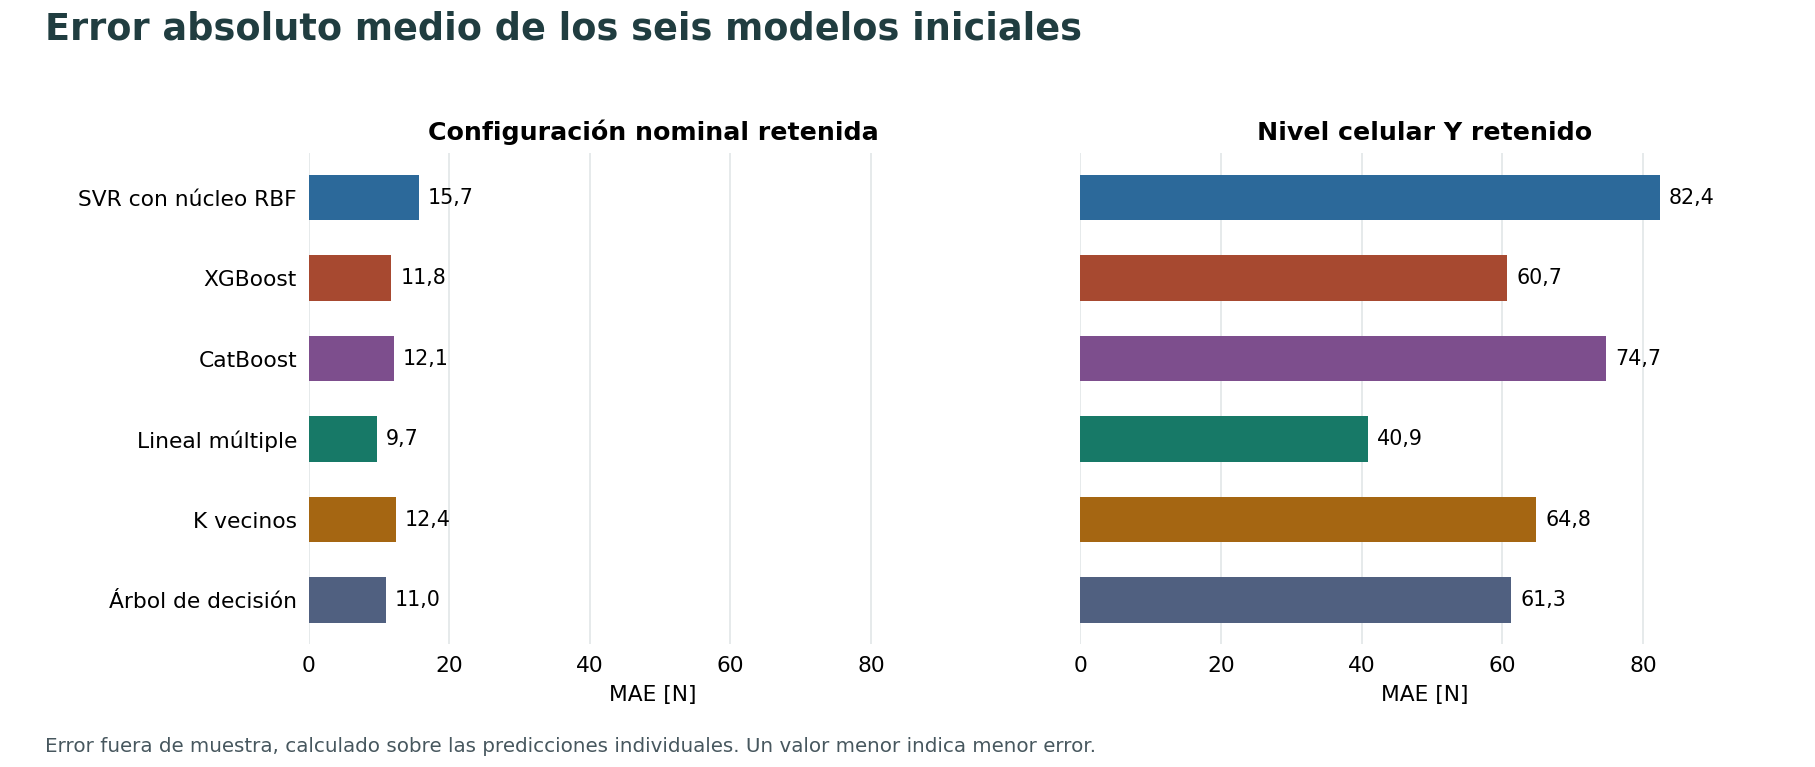

In [8]:
columnas_iniciales = ["procedimiento","grupo","feature_set","MAE_N","RMSE_N","MedAE_N","R2_OOF","sesgo_N","DE_MAE_fold_N","tiempo_ajuste_s","tiempo_prediccion_s"]
for p in PROTOCOLOS:
    print(PROTO[p])
    t = resumen(p).reset_index()[columnas_iniciales].copy()
    t["Observaciones"] = ["Menor MAE que Ridge" if val < valor(p,"Ridge_historico") else "MAE igual o mayor que Ridge" for val in t.MAE_N]
    t["procedimiento"] = t.procedimiento.map(nombre)
    tabla(t.rename(columns={"procedimiento":"Modelo","grupo":"Grupo","feature_set":"Entradas","sesgo_N":"Sesgo [N]","DE_MAE_fold_N":"DE MAE pliegues [N]","tiempo_ajuste_s":"Ajuste [s]","tiempo_prediccion_s":"Predicción [s]"}))
figura(1)
caja(f"En configuraciones, {nombre(mejor)} alcanza el menor MAE inicial con {fmt(principal.loc[mejor,'MAE_N'])} N. Las seis recetas abarcan {fmt(principal.MAE_N.min())}–{fmt(principal.MAE_N.max())} N.",
     f"Superan en MAE a la mediana: {codigos(principal[principal.MAE_N < valor('configuracion','Dummy_mediana')].index)}. Superan a Ridge: {codigos(principal[principal.MAE_N < valor('configuracion','Ridge_historico')].index)}.",
     "El contraste con una mediana permite detectar señal predictiva asociada a las geometrías de esta campaña.",
     "El mínimo observado depende de la muestra y del protocolo. La separación entre dos valores cercanos requiere mirar sus diferencias por caso.",
     "Evaluar también RMSE, dispersión, costos y referencia por nivel antes de recomendar.")

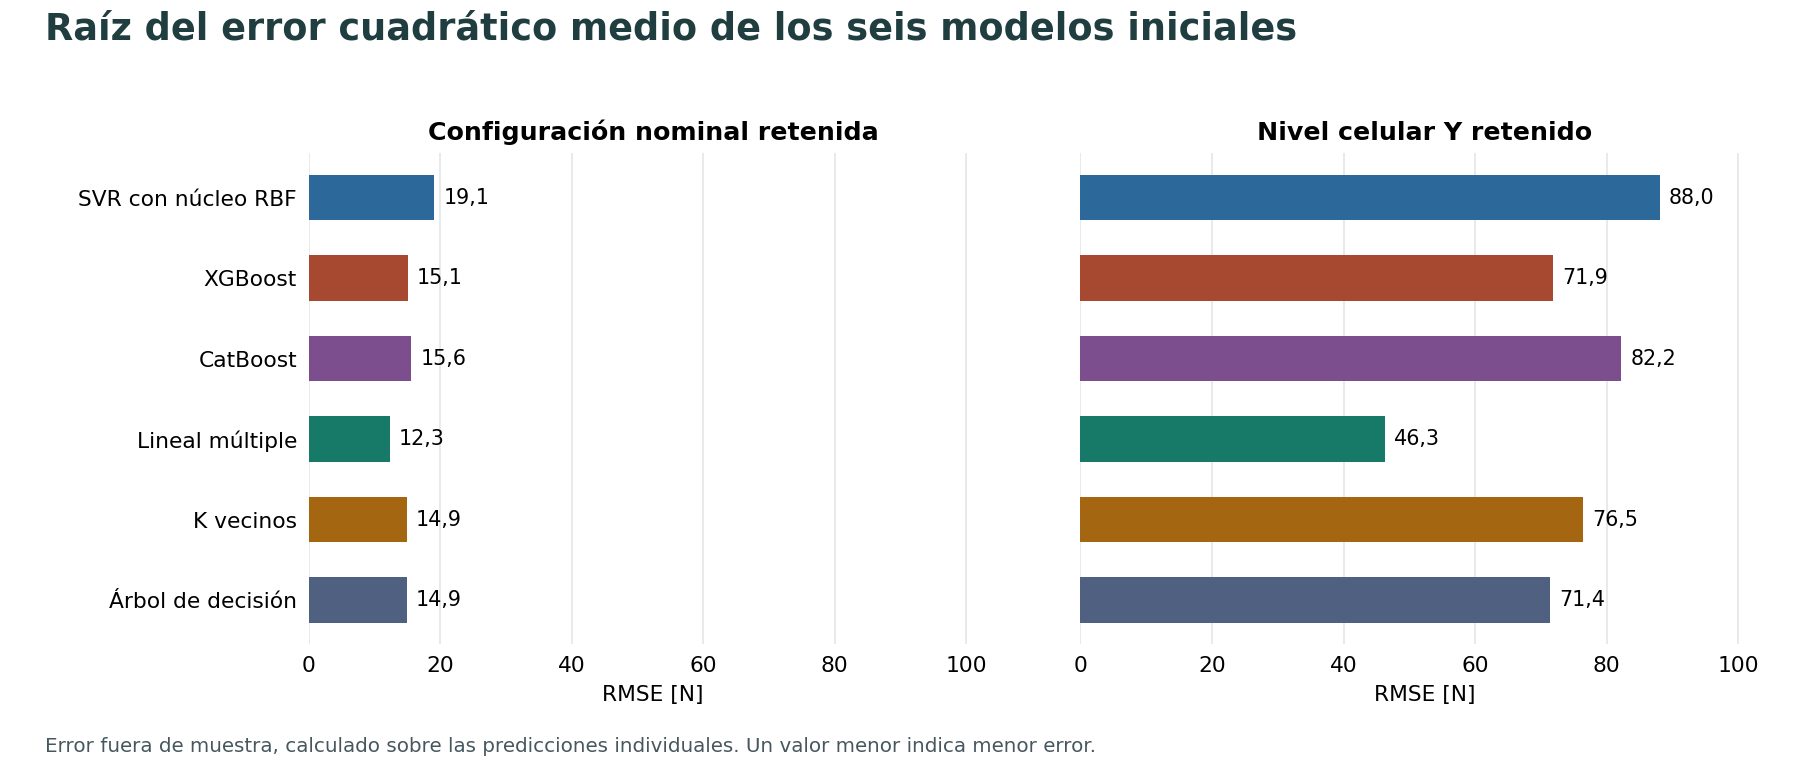

In [9]:
figura(2)
mejor_rmse = principal.RMSE_N.idxmin()
gap_rmse = (principal.RMSE_N - principal.MAE_N).idxmax()
caja(f"{nombre(mejor_rmse)} tiene el menor RMSE por configuración ({fmt(principal.loc[mejor_rmse,'RMSE_N'])} N). La mayor separación RMSE–MAE corresponde a {nombre(gap_rmse)} ({fmt(principal.loc[gap_rmse,'RMSE_N']-principal.loc[gap_rmse,'MAE_N'])} N).",
     "La diferencia RMSE–MAE aumenta cuando los tamaños de error son desiguales entre especímenes.",
     "Las observaciones de mayor error apuntan a geometrías que merecen contraste con la ficha de ensayo.",
     "El RMSE agrega discrepancias y no identifica el mecanismo que originó una observación extrema.",
     "Localizar por identificador las discrepancias más grandes y revisar los residuos.")

## 11. Diagnóstico de errores

Las figuras distinguen tres niveles de agregación. La brecha entrenamiento–validación da el mismo peso a cada pliegue. Los diagramas de predicción y de error absoluto muestran especímenes individuales. Los residuos se presentan para el modelo con menor MAE inicial y dos familias elegidas con mayor frecuencia en el cribado **interno** del protocolo principal.

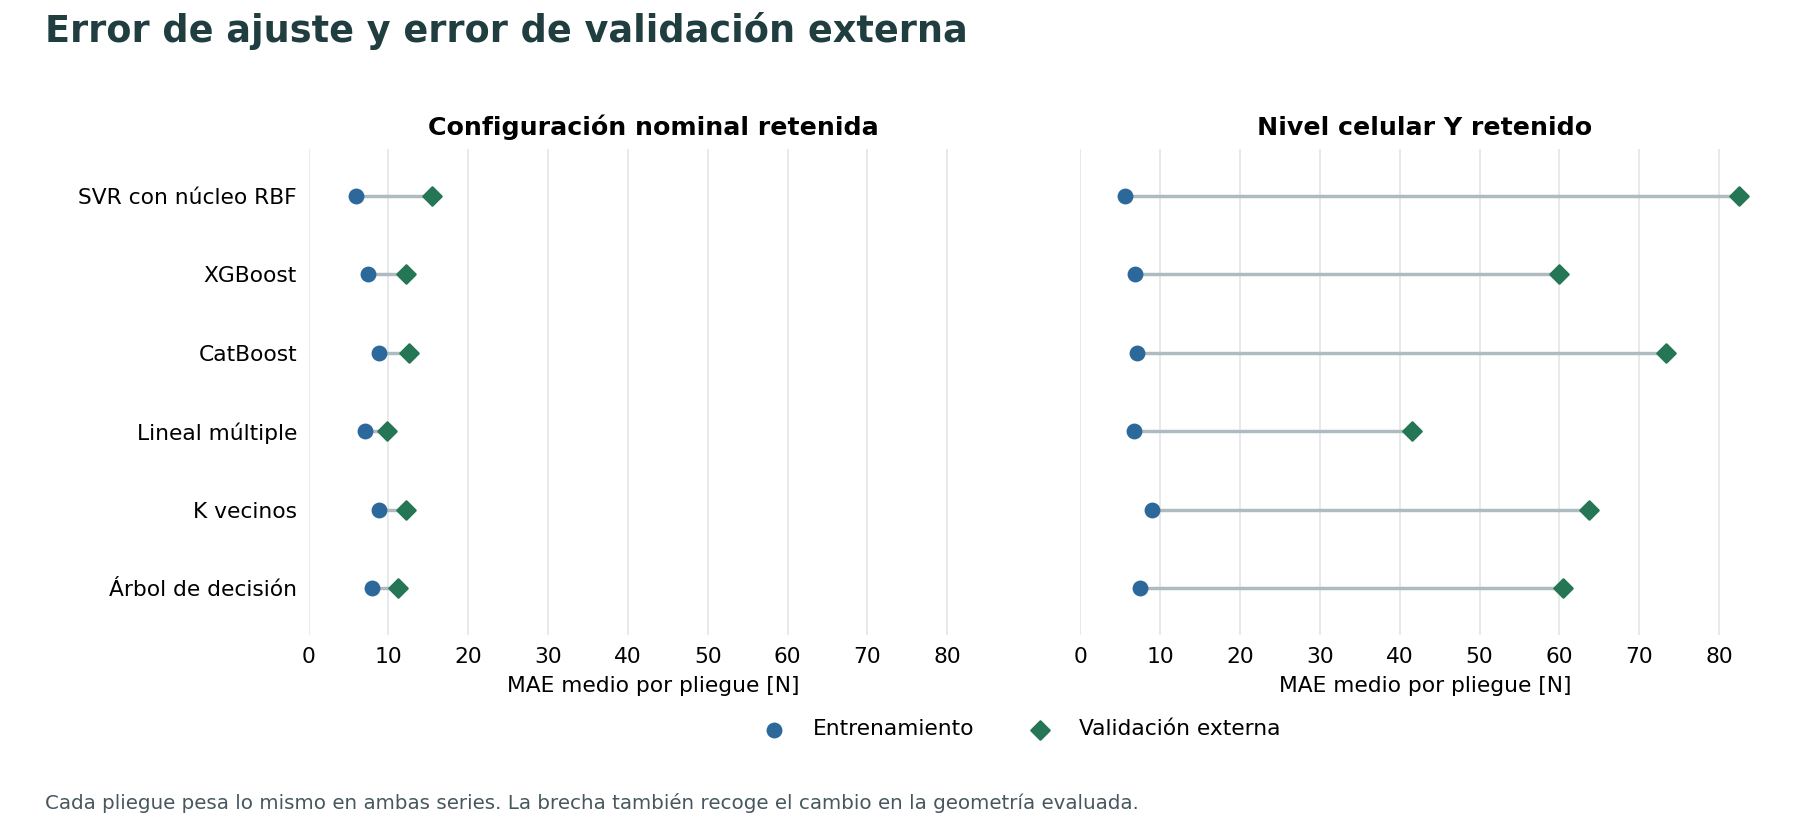

protocolo,Modelo,configuracion,familia
,Árbol de decisión,"3,246","52,981"
,XGBoost,"4,720","53,129"
,CatBoost,"3,720","66,261"


In [10]:
figura(3)
brecha = (folds[folds.procedimiento.isin(MODELOS)].assign(brecha_N=lambda x:x.MAE_validacion_N-x.MAE_train_N)
          .groupby(["protocolo","procedimiento"]).brecha_N.mean().unstack("protocolo"))
arboles = ["Arbol_decision","XGBoost","CatBoost"]
tabla(brecha.loc[arboles].rename(index=nombre).rename_axis("Modelo").reset_index())
mayor_brecha = brecha.configuracion.idxmax()
caja(f"La mayor brecha media por configuración es {fmt(brecha.loc[mayor_brecha,'configuracion'])} N en {nombre(mayor_brecha)}.",
     "Una brecha positiva es compatible con adaptación al entrenamiento. Al retirar un nivel también se desplaza la distribución de las entradas.",
     "Un árbol puede reconocer regiones apoyadas por geometrías conocidas y perder precisión al reservar una de esas regiones.",
     "Los ajustes de entrenamiento reutilizan observaciones. La brecha combina optimismo de ajuste y dificultad de generalización.",
     "Examinar los errores externos y las hojas o profundidades observadas antes de atribuir sobreajuste.")

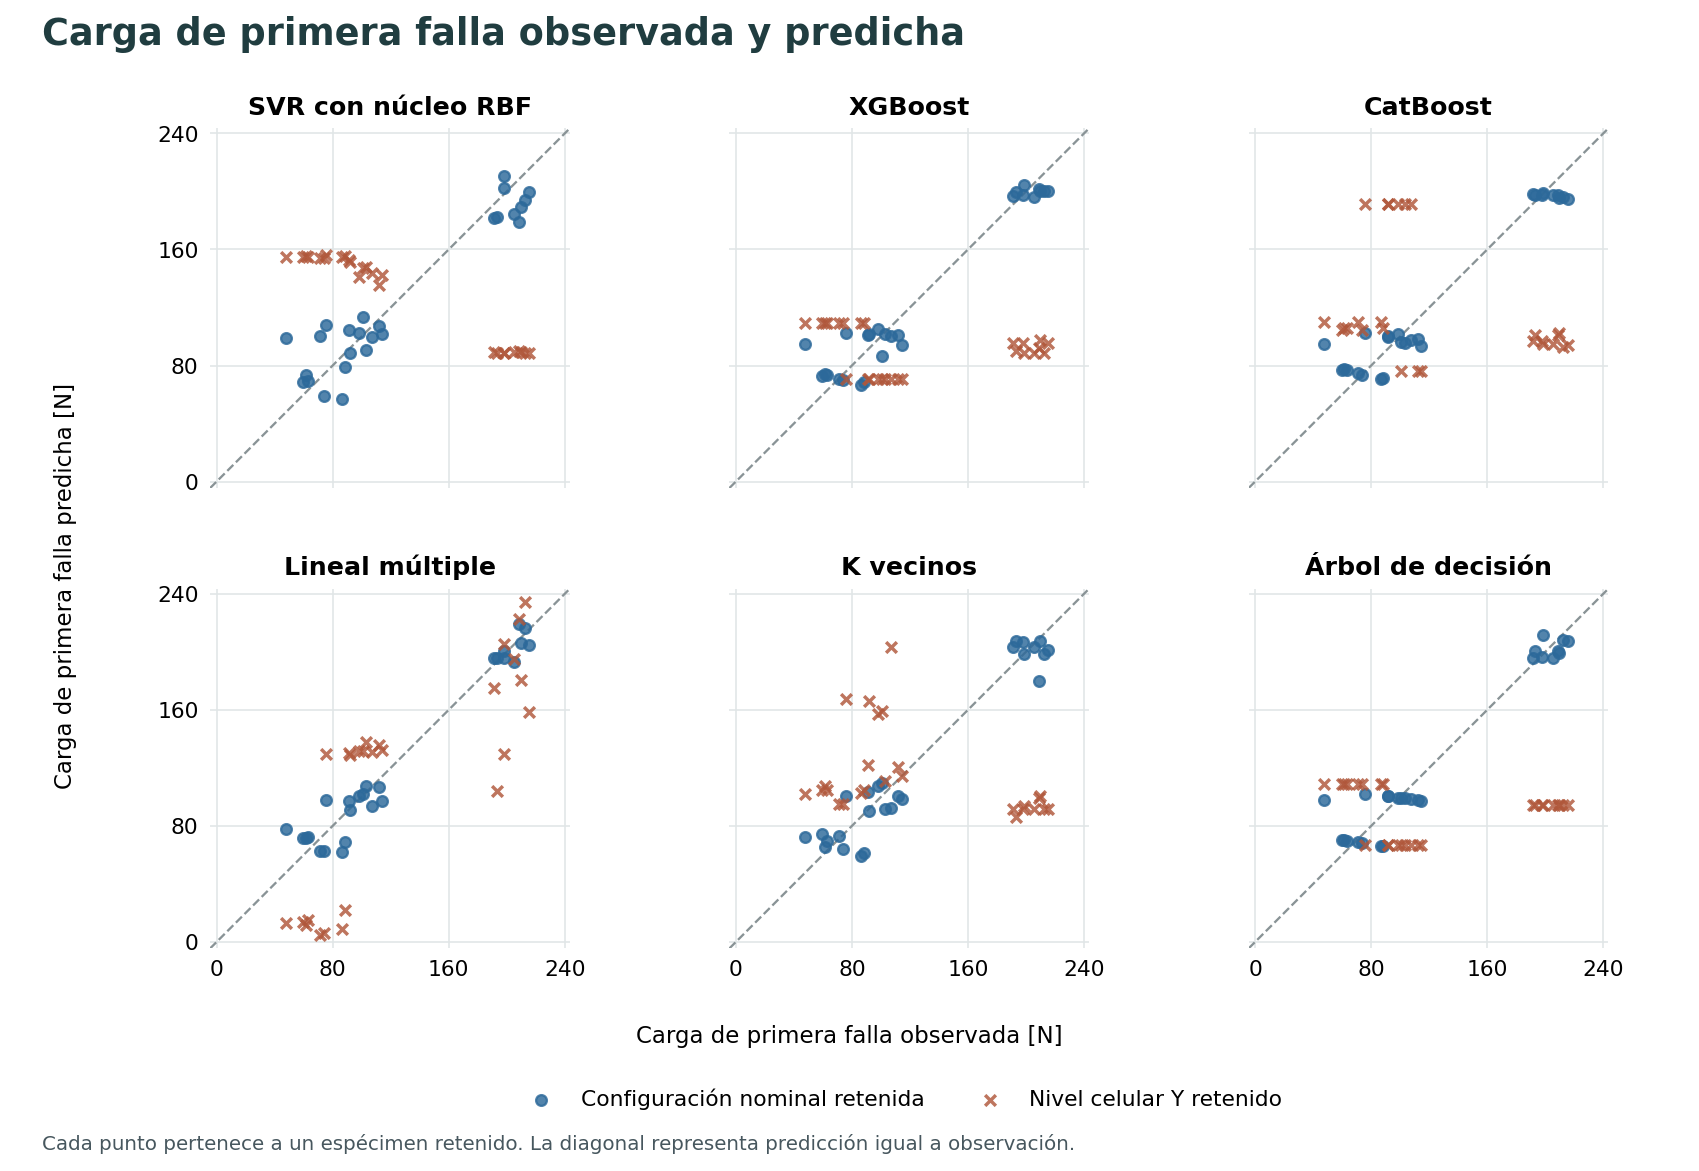

protocolo,procedimiento,Case_n,n_cells_Y,observado_N,predicho_N,error_absoluto_N
configuracion,Arbol_decision,1,4,"47,550","98,086","50,536"
configuracion,CatBoost,1,4,"47,550","94,789","47,239"
configuracion,KNN,19,6,"208,740","179,807","28,933"
configuracion,Lineal_multiple,1,4,"47,550","77,831","30,281"
configuracion,SVR_RBF,1,4,"47,550","99,211","51,661"
configuracion,XGBoost,1,4,"47,550","94,693","47,143"
familia,Arbol_decision,22,6,"215,520","94,560","120,960"
familia,CatBoost,22,6,"215,520","94,486","121,034"
familia,KNN,22,6,"215,520","91,553","123,967"
familia,Lineal_multiple,25,6,"193,200","104,411","88,789"


In [11]:
figura(4)
iniciales_oof = oof[oof.procedimiento.isin(MODELOS)].copy()
maximos = iniciales_oof.loc[iniciales_oof.groupby(["protocolo","procedimiento"]).error_absoluto_N.idxmax(),
                            ["protocolo","procedimiento","Case_n","n_cells_Y","observado_N","predicho_N","error_absoluto_N"]]
tabla(maximos)
peor_caso = maximos[maximos.protocolo.eq("configuracion")].nlargest(1,"error_absoluto_N").iloc[0]
caja(f"El mayor error absoluto inicial por configuración fue {fmt(peor_caso.error_absoluto_N)} N en el caso {int(peor_caso.Case_n)} con {nombre(peor_caso.procedimiento)}.",
     f"Su carga observada fue {fmt(peor_caso.observado_N)} N y su predicción {fmt(peor_caso.predicho_N)} N. Los puntos distantes de la diagonal concentran error.",
     "La geometría nominal puede compartir nivel celular con otras probetas y aun presentar una respuesta distinta.",
     "Un error grande señala un caso para inspección documental. Las mediciones permanecen en el análisis.",
     "Revisar la ficha del caso y mantener todos los especímenes observados en los resultados publicados.")

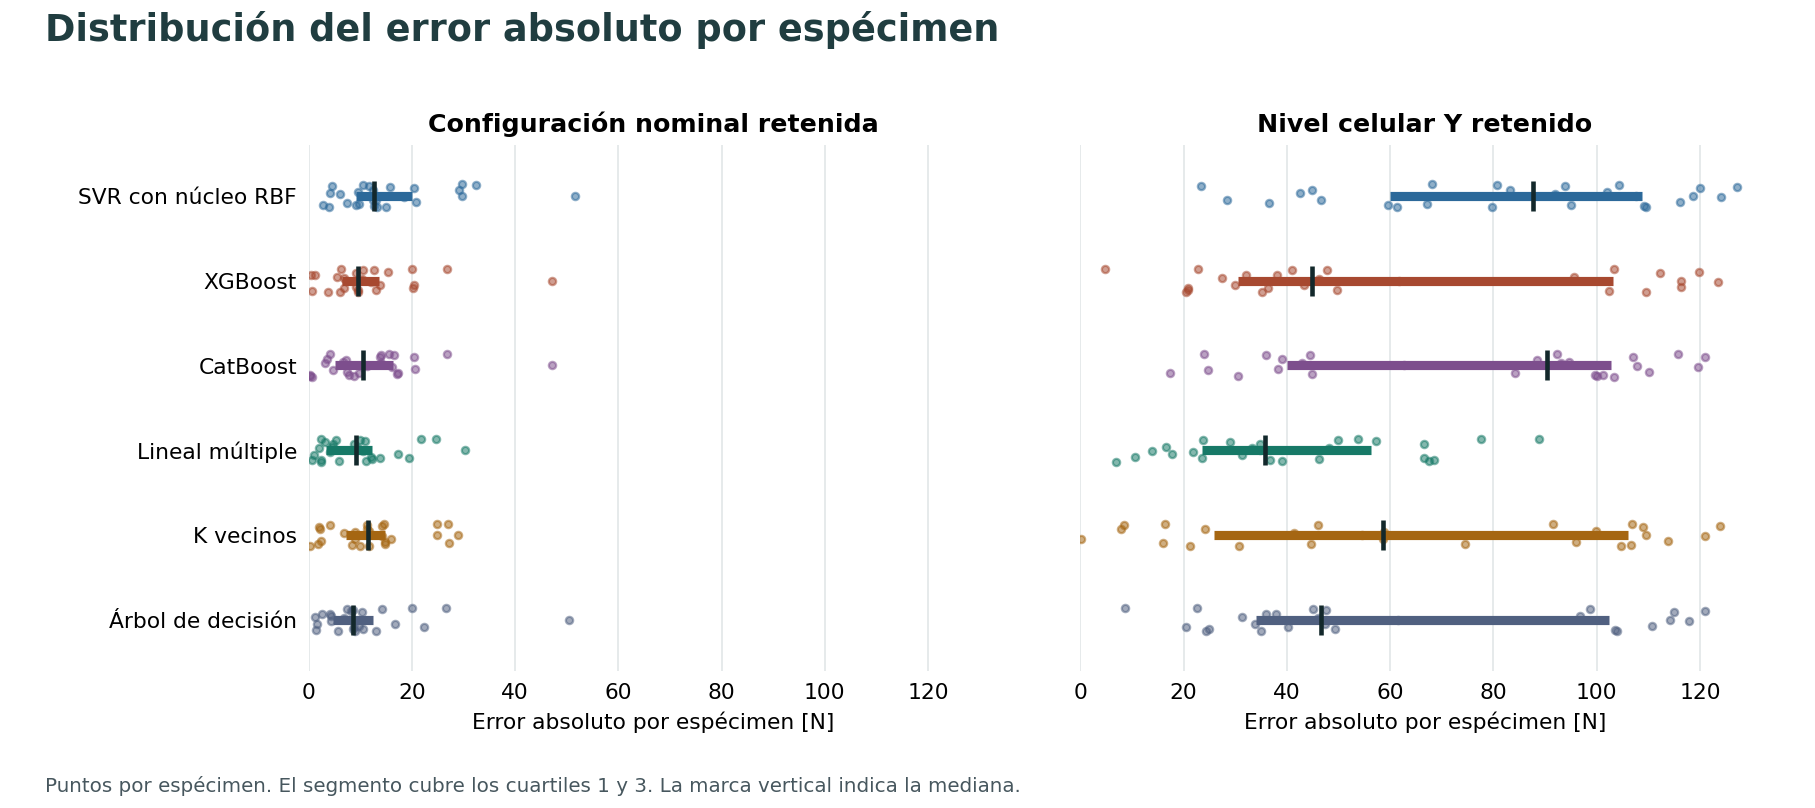

In [12]:
figura(5)
ultimos = principal.DE_error_absoluto_N.idxmax()
caja(f"{nombre(ultimos)} presenta la mayor DE de error absoluto individual por configuración ({fmt(principal.loc[ultimos,'DE_error_absoluto_N'])} N). Su MedAE es {fmt(principal.loc[ultimos,'MedAE_N'])} N.",
     "Los cuantiles muestran dónde se concentra la mayor parte del error. Las colas ayudan a leer la diferencia entre la mediana y el RMSE.",
     "Diferencias entre geometrías próximas pueden incluir dimensiones no capturadas por la tabla.",
     "Las distribuciones comparten especímenes. Las comparaciones de modelos deben emparejar los casos.",
     "Calcular los cambios de error sobre el mismo espécimen frente al control histórico.")

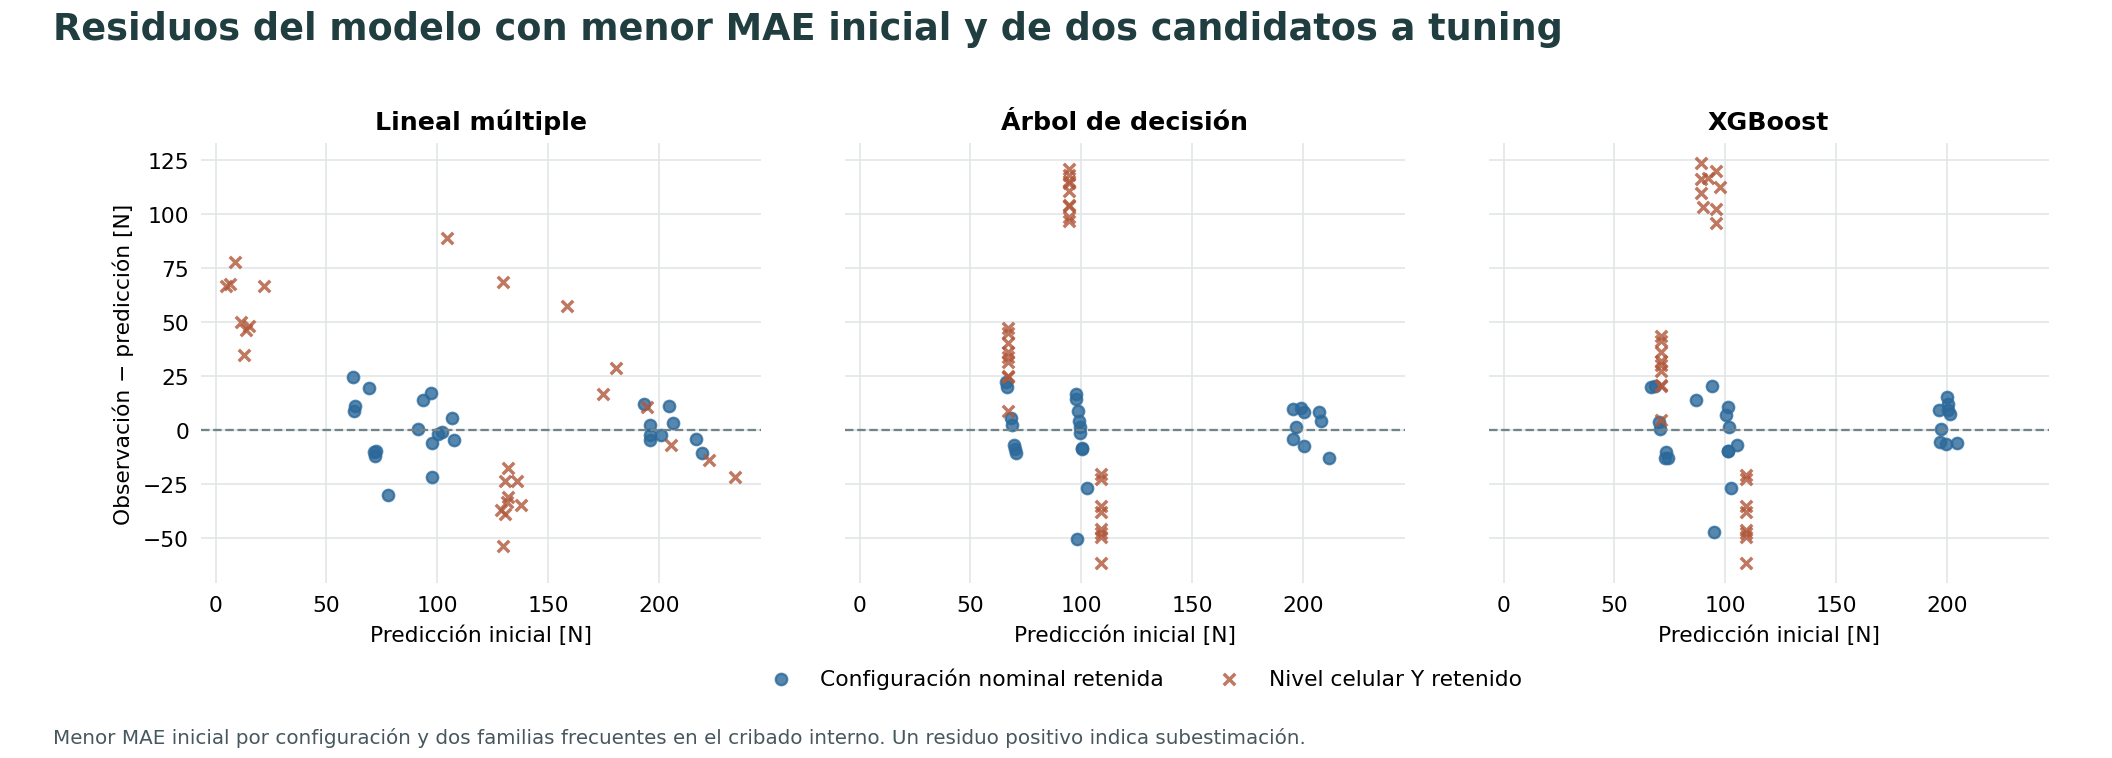

In [13]:
figura(6)
conteos = seleccion[seleccion.protocolo.eq("configuracion")].familia_real.value_counts()
sv = principal.loc["SVR_RBF"]
caja(f"El cribado interno por configuración priorizó con mayor frecuencia {nombre(conteos.idxmax())} ({int(conteos.max())} reservas). Para SVR, el sesgo agregado es {fmt(sv.sesgo_N)} N y la DE de MAE por pliegue {fmt(sv.DE_MAE_fold_N)} N.",
     "En este gráfico la convención de residuo es observación menos predicción. La tabla de métricas define el sesgo con el signo contrario.",
     "Un patrón residual por escala de carga puede indicar que los descriptores disponibles representan de modo desigual los niveles arquitectónicos.",
     "Una tendencia visual de residuos no identifica una causa material ni estima por sí misma la incertidumbre de una predicción.",
     "Conservar en el diagnóstico también las familias con errores altos y separar tendencia de dispersión.")

## 12. Selección de candidatos a tuning

La selección se repite dentro de cada entrenamiento externo. Se criban las cinco familias con hiperparámetros ajustables. Entre las que caen en la banda interna se favorece menor dispersión del MAE por grupo, después menor MAE y finalmente el orden de complejidad congelado. La banda es operativa. Mínimos cuadrados permanece como referencia lineal.

In [14]:
frecuencias = (seleccion.groupby(["protocolo","familia_real"]).size()
               .reindex(pd.MultiIndex.from_product([PROTOCOLOS, CFG["espacios"]], names=["protocolo","familia_real"]),fill_value=0)
               .rename("reservas_priorizadas").reset_index())
tabla(frecuencias)
caja(f"Se seleccionaron {CFG['numero_familias_tuning']} candidatas por entrenamiento. La familia más frecuente por configuración fue {nombre(conteos.idxmax())}.",
     f"Cada puesto se decide con MAE interno y MAD de errores por grupo entre opciones situadas a {fmt(CFG['banda_cribado_N'])} N de la menor MAE restante.",
     "El cribado favorece respuestas reproducibles a través de las geometrías reservadas en el entrenamiento.",
     "La composición de candidatas puede cambiar al retirar un nivel. Las frecuencias dependen de esta campaña y del presupuesto fijado.",
     "Evaluar los rangos y el selector como procedimientos adaptativos, conservando la familia efectivamente utilizada en cada reserva.")

protocolo,familia_real,reservas_priorizadas
configuracion,SVR_RBF,0
configuracion,XGBoost,17
configuracion,CatBoost,2
configuracion,KNN,10
configuracion,Arbol_decision,19
familia,SVR_RBF,3
familia,XGBoost,0
familia,CatBoost,2
familia,KNN,1
familia,Arbol_decision,0


## 13. Espacios de búsqueda y presupuesto

El espacio discreto se define antes de entrenar. Se incluye la configuración inicial y se muestrean sin reposición las alternativas para cada familia. Las muestras se conservan en el mismo orden para poder reproducir las trayectorias. El error externo se consulta después de la selección interna.

In [15]:
tabla(pd.DataFrame([{"Modelo":nombre(m),"Espacio discreto":json.dumps(v,ensure_ascii=False),"Configuraciones por búsqueda":CFG["presupuesto_por_candidata"]} for m,v in CFG["espacios"].items()]))
res_busquedas = busqueda.groupby(["protocolo","fold","familia_real"]).agg(evaluadas=("orden","nunique"), minima_MAE_interna_N=("MAE_interno_N","min")).reset_index()
assert res_busquedas.evaluadas.eq(CFG["presupuesto_por_candidata"]).all()
caja(f"Cada una de las {len(res_busquedas)} búsquedas evaluó {CFG['presupuesto_por_candidata']} configuraciones. Semilla general {CFG['semilla']}.",
     "Un presupuesto igual permite comparar procedimientos de búsqueda bajo el mismo número de evaluaciones. El tiempo de cada ajuste puede diferir.",
     "Profundidades y tamaños de hoja acotados reducen el riesgo de tratar unos pocos especímenes como un régimen mecánico.",
     "El espacio es discreto. El mínimo interno es específico del conjunto explorado y los grupos de entrenamiento.",
     "Mantener el presupuesto fijado y comprobar que el beneficio interno se conserva en las reservas externas.")

Modelo,Espacio discreto,Configuraciones por búsqueda
SVR con núcleo RBF,"{""C"": [25, 100, 250], ""epsilon"": [2, 5, 10], ""gamma"": [""scale"", 0.03, 0.3]}",8
XGBoost,"{""max_depth"": [1, 2, 3], ""n_estimators"": [40, 60, 80], ""learning_rate"": [0.03, 0.075, 0.15], ""min_child_weight"": [1, 2, 4], ""reg_lambda"": [1, 3, 10]}",8
CatBoost,"{""iterations"": [40, 60, 80], ""depth"": [1, 2, 3], ""learning_rate"": [0.03, 0.075, 0.15], ""l2_leaf_reg"": [2, 5, 12]}",8
K vecinos,"{""n_neighbors"": [2, 3, 4, 5, 7], ""weights"": [""uniform"", ""distance""], ""p"": [1, 2]}",8
Árbol de decisión,"{""max_depth"": [1, 2, 3], ""min_samples_leaf"": [2, 3, 4]}",8


## 14. Optimización dentro de los entrenamientos

Para cada familia priorizada se conserva el mínimo MAE interno, usando los desempates fijados. De esas dos familias el selector elige una usando exclusivamente sus resultados internos. La evolución muestra cuánto se reduce el mejor MAE interno respecto a la configuración inicial de cada búsqueda. La primera evaluación define el valor de referencia de cada serie.

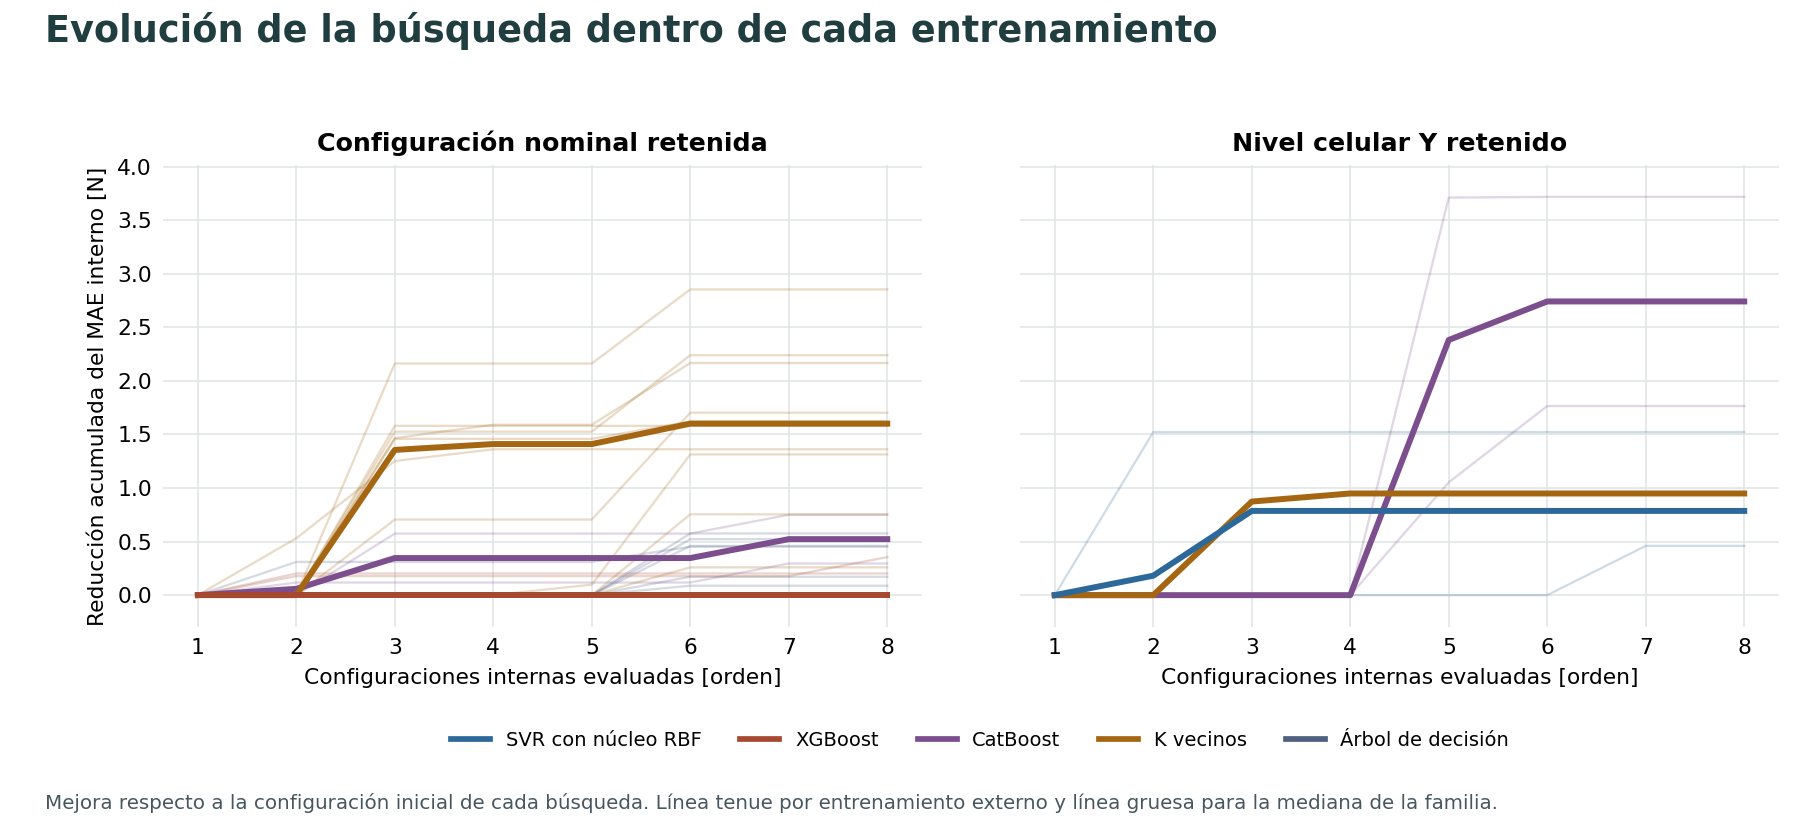

protocolo,familia_real,Búsquedas,Mejora mediana [N],Mejora máxima [N]
configuracion,Arbol_decision,19,"0,000","0,576"
configuracion,CatBoost,2,"0,523","0,750"
configuracion,KNN,10,"1,601","2,853"
configuracion,XGBoost,17,"0,000","0,355"
familia,CatBoost,2,"2,741","3,717"
familia,KNN,1,"0,949","0,949"
familia,SVR_RBF,3,"0,786","1,522"


In [16]:
figura(8)
trayectorias = (busqueda.sort_values("orden").groupby(["protocolo","fold","familia_real"]).mejor_acumulado_N.agg(["first","last"]).reset_index())
trayectorias["mejora_interna_N"] = trayectorias["first"] - trayectorias["last"]
tabla(trayectorias.groupby(["protocolo","familia_real"]).mejora_interna_N.agg(["count","median","max"]).reset_index().rename(columns={"count":"Búsquedas","median":"Mejora mediana [N]","max":"Mejora máxima [N]"}))
caja(f"En {int((trayectorias.mejora_interna_N>1e-10).sum())} de {len(trayectorias)} búsquedas descendió el mejor MAE interno respecto del primer paso.",
     "La mejor pérdida acumulada solo puede mantenerse o disminuir. Su tendencia no mide por sí sola el beneficio en casos retenidos.",
     "Cambiar el grado de suavidad o de partición puede adaptar el modelo a la densidad de geometrías del entrenamiento.",
     "Los pliegues de entrenamiento se solapan y los modelos criban familias distintas. Las curvas no son ensayos independientes.",
     "Medir el efecto del tuning con predicciones externas, emparejadas con las configuraciones iniciales de las mismas familias.")

## 15. Comparación final

Las tablas integran Ridge histórico, el predictor ingenuo de mediana, la media por nivel, los seis modelos iniciales y los tres procedimientos adaptativos. **ΔMAE frente a Ridge** comparte protocolo y observaciones. **ΔMAE por tuning** contrasta cada ajuste con la receta inicial de la familia efectivamente escogida para cada caso. El tiempo de búsqueda es compartido por procedimientos y se informa aparte.

Configuración nominal retenida


Modelo,grupo,Configuración,feature_set,Optimizado,MAE_N,RMSE_N,MedAE_N,R2_OOF,sesgo_N,delta_MAE_vs_Ridge_N,tiempo_ajuste_s,tiempo_prediccion_s,tiempo_busqueda_s,DE_MAE_fold_N
Ridge histórico,referencia,"α=1, solucionador svd",A,No,"13,247","16,346","11,941","0,923","-0,396","0,000","0,166","0,069","0,000","9,677"
Mediana de entrenamiento,referencia,Mediana del entrenamiento,sin_geometria,No,"49,748","64,699","35,890","-0,213","-24,418","36,502","0,069","0,029","0,000","41,054"
Media por nivel Y,referencia,"Media por Y, con media de entrenamiento para nivel ausente",n_cells_Y,No,"10,126","12,308","8,688","0,956","0,098","-3,121","0,071","0,034","0,000","7,041"
SVR con núcleo RBF,A_materiales,"RBF, C=100, ε=5 N, γ=scale",A,No,"15,651","19,096","12,633","0,894","-1,241","2,404","0,164","0,069","0,000","11,120"
XGBoost,A_materiales,"60 árboles, profundidad 2, η=0.075",A,No,"11,754","15,093","9,594","0,934","0,094","-1,493","0,443","0,078","0,000","9,947"
CatBoost,A_materiales,"60 iteraciones, profundidad 2, η=0.075",A,No,"12,148","15,596","10,508","0,930","-0,081","-1,098","0,856","0,096","0,000","10,243"
Lineal múltiple,B_clasicos,Mínimos cuadrados con intercepto y base de rango completo,A,No,"9,664","12,308","9,136","0,956","-0,289","-3,583","0,188","0,072","0,000","7,905"
K vecinos,B_clasicos,"k=3, p=2, pesos uniform",A,No,"12,429","14,923","11,515","0,935","-1,502","-0,818","0,163","0,098","0,000","8,104"
Árbol de decisión,B_clasicos,"Profundidad 2, hoja mínima 2",A,No,"10,956","14,892","8,580","0,936","0,328","-2,291","0,164","0,067","0,000","10,637"
Primera del cribado,procedimiento_adaptativo,Familia y parámetros elegidos dentro del entrenamiento,A,Sí,"11,263","14,643","8,757","0,938","-0,016","-1,984","0,205","0,076","32,598","9,825"


Nivel celular Y retenido


Modelo,grupo,Configuración,feature_set,Optimizado,MAE_N,RMSE_N,MedAE_N,R2_OOF,sesgo_N,delta_MAE_vs_Ridge_N,tiempo_ajuste_s,tiempo_prediccion_s,tiempo_busqueda_s,DE_MAE_fold_N
Ridge histórico,referencia,"α=1, solucionador svd",A,No,"57,637","60,428","64,520","-0,058","-28,847","0,000","0,021","0,009","0,000","17,145"
Mediana de entrenamiento,referencia,Mediana del entrenamiento,sin_geometria,No,"97,511","99,009","96,377","-1,840","17,796","39,874","0,009","0,004","0,000","16,229"
Media por nivel Y,referencia,"Media por Y, con media de entrenamiento para nivel ausente",n_cells_Y,No,"80,593","87,521","84,392","-1,219","-1,494","22,955","0,009","0,005","0,000","38,870"
SVR con núcleo RBF,A_materiales,"RBF, C=100, ε=5 N, γ=scale",A,No,"82,358","88,039","87,602","-1,246","3,045","24,720","0,022","0,009","0,000","33,871"
XGBoost,A_materiales,"60 árboles, profundidad 2, η=0.075",A,No,"60,684","71,889","44,810","-0,497","-35,888","3,046","0,037","0,010","0,000","44,640"
CatBoost,A_materiales,"60 iteraciones, profundidad 2, η=0.075",A,No,"74,726","82,248","90,312","-0,960","-6,501","17,089","0,084","0,012","0,000","34,093"
Lineal múltiple,B_clasicos,Mínimos cuadrados con intercepto y base de rango completo,A,No,"40,915","46,337","35,745","0,378","-15,052","-16,723","0,032","0,011","0,000","13,564"
K vecinos,B_clasicos,"k=3, p=2, pesos uniform",A,No,"64,849","76,459","58,655","-0,694","-11,706","7,211","0,020","0,010","0,000","41,243"
Árbol de decisión,B_clasicos,"Profundidad 2, hoja mínima 2",A,No,"61,289","71,374","46,638","-0,476","-36,654","3,652","0,020","0,009","0,000","42,247"
Primera del cribado,procedimiento_adaptativo,Familia y parámetros elegidos dentro del entrenamiento,A,Sí,"81,106","87,837","88,770","-1,235","0,752","23,468","0,021","0,009","1,865","37,849"


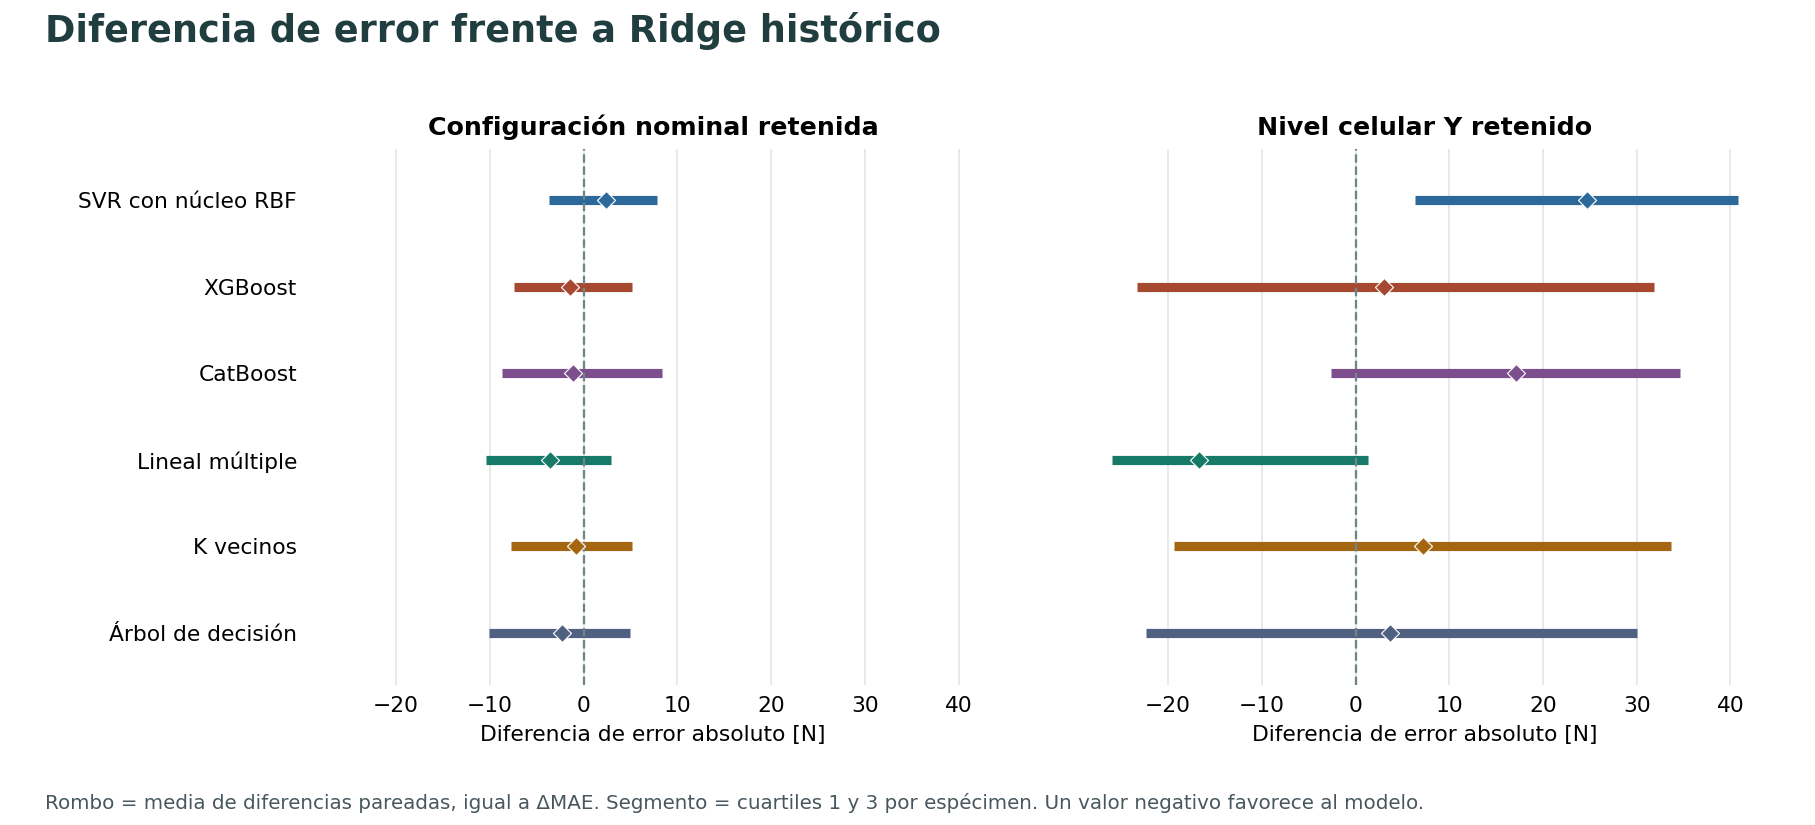

In [17]:
orden = ["Ridge_historico","Dummy_mediana","Media_por_nivel",*MODELOS,"Tuning_rango_1","Tuning_rango_2","Selector_tuning"]
for p in PROTOCOLOS:
    print(PROTO[p])
    t = resumen(p, orden).reset_index().copy()
    t["Configuración"] = t.procedimiento.map(ficha_corta)
    t["Optimizado"] = np.where(t.procedimiento.str.startswith(("Tuning","Selector")),"Sí","No")
    t["Modelo"] = t.procedimiento.map(nombre)
    tabla(t[["Modelo","grupo","Configuración","feature_set","Optimizado","MAE_N","RMSE_N","MedAE_N","R2_OOF","sesgo_N","delta_MAE_vs_Ridge_N","tiempo_ajuste_s","tiempo_prediccion_s","tiempo_busqueda_s","DE_MAE_fold_N"]])
figura(7)
deltas = principal.delta_MAE_vs_Ridge_N.sort_values()
caja(f"La mayor reducción frente a Ridge por configuración corresponde a {nombre(deltas.index[0])}: ΔMAE {fmt(deltas.iloc[0])} N.",
     "En cada caso se resta el error absoluto de Ridge al del modelo. La media reproduce la diferencia de MAE entre ambos.",
     "Superar a una referencia lineal regularizada dentro del diseño sugiere comprobar si el beneficio persiste en regiones geométricas retenidas.",
     "Las diferencias por caso pueden cambiar de signo y los cuartiles del gráfico describen heterogeneidad.",
     "Consultar también la referencia por nivel y las reservas con cambio de signo antes de adoptar una receta.")

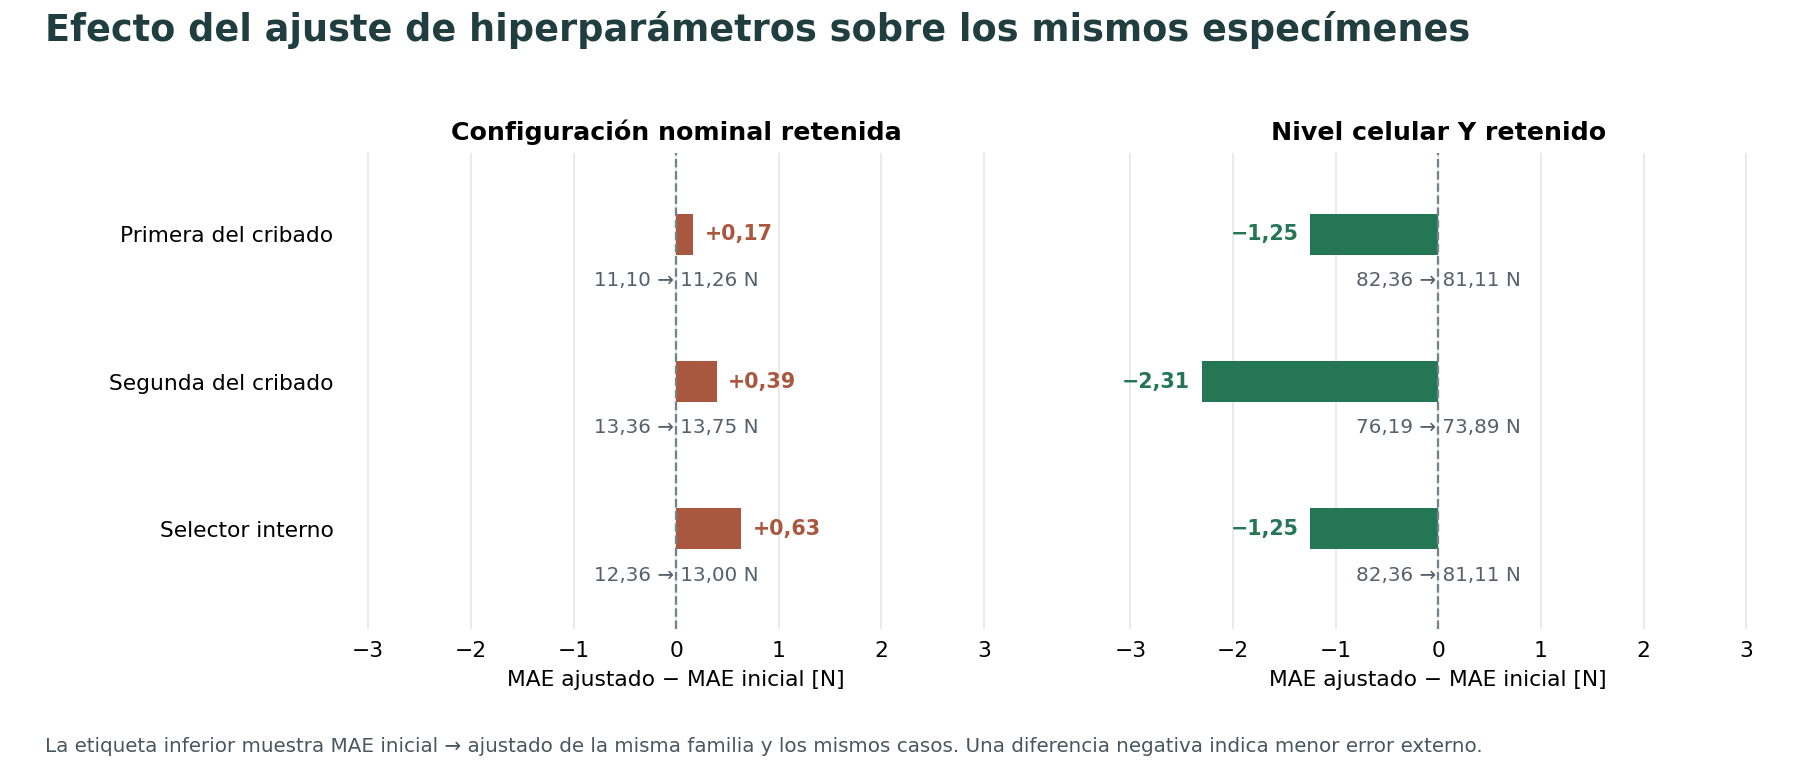

In [18]:
figura(9)
delta_sel = {p:valor(p,"Selector_tuning","delta_MAE_vs_inicial_misma_familia_N") for p in PROTOCOLOS}
frases = {p:("redujo" if v < -1e-9 else "aumentó" if v > 1e-9 else "mantuvo") for p,v in delta_sel.items()}
caja(f"El tuning del selector {frases['configuracion']} el MAE externo por configuración en {fmt(abs(delta_sel['configuracion']))} N y lo {frases['familia']} al retirar niveles en {fmt(abs(delta_sel['familia']))} N.",
     "La comparación empareja espécimen y familia entre los dos ajustes. Los procedimientos por rango se evalúan completos para evitar escoger el mejor rango después de ver las reservas.",
     "Una configuración que se ajusta mejor entre geometrías conocidas puede transferirse de modo distinto a una arquitectura retenida.",
     "La familia seleccionada puede variar entre reservas, por lo que el resultado se atribuye al procedimiento completo de selección.",
     "Aplicar la regla de adopción registrada para contrastar el selector con un procedimiento fijo y su referencia operativa.")

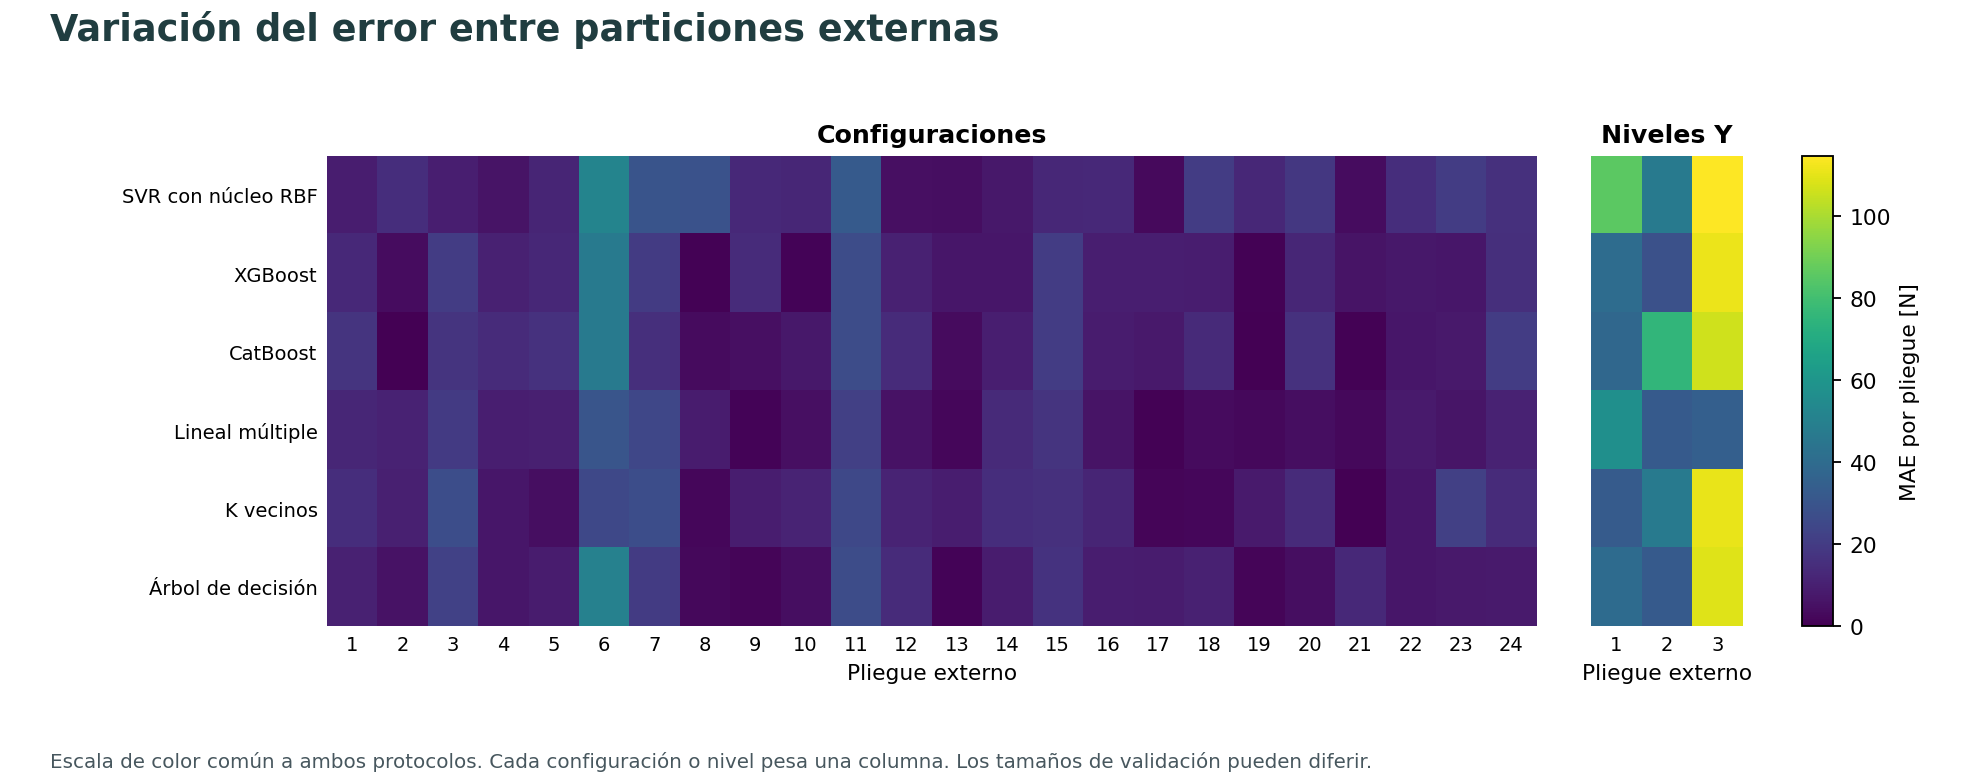

In [19]:
figura(10)
estable_familia = transferencia.DE_MAE_fold_N.idxmin()
caja(f"Por configuración, {nombre(mas_estable)} presenta la menor DE de los MAE por pliegue ({fmt(principal.loc[mas_estable,'DE_MAE_fold_N'])} N). Al retirar niveles corresponde a {nombre(estable_familia)} ({fmt(transferencia.loc[estable_familia,'DE_MAE_fold_N'])} N).",
     "La dispersión muestra cuánto cambia el error entre reservas. Su valor depende tanto del modelo como de la composición del pliegue.",
     "Una reserva que reúne arquitecturas o cargas extremas puede concentrar errores para varios modelos.",
     "Hay tamaños de prueba distintos. Con tres reservas de nivel, una sola puede dominar la dispersión.",
     "Leer estabilidad junto al MAE y revisar qué geometrías componen los pliegues que concentran errores.")

## 16. Interpretación estadística y mecánica

Se contrastan la referencia lineal, las distancias y las particiones en árboles con la señal arquitectónica observada en el EDA. Los coeficientes lineales se expresan en N por unidad de la característica original y corresponden a una base específica de cada entrenamiento. Las distancias de K vecinos se expresan en el espacio escalado.

In [20]:
diag = pd.read_csv(TABLAS/"diagnosticos_modelos.csv")
coef = pd.read_csv(TABLAS/"coeficientes_ols.csv")
ol = diag[diag.procedimiento.eq("Lineal_multiple") & diag.protocolo.eq("configuracion")]
co = coef[coef.protocolo.eq("configuracion") & coef.estado.eq("retenida")]
coef_resumen = co.groupby(["variable","unidad_variable"]).coeficiente_N_por_unidad.agg(["count","min","median","max"]).reset_index()
tabla(coef_resumen.rename(columns={"count":"Pliegues retenida","min":"Pendiente mínima","median":"Pendiente mediana","max":"Pendiente máxima"}))
mejor_nl = principal.drop(index="Lineal_multiple").MAE_N.idxmin()
d_nl = principal.loc[mejor_nl,"MAE_N"]-principal.loc["Lineal_multiple","MAE_N"]
caja(f"OLS tuvo MAE {fmt(valor('configuracion','Lineal_multiple'))} N y R² {fmt(valor('configuracion','Lineal_multiple','R2_OOF'),3)}. El menor MAE no lineal fue el de {nombre(mejor_nl)} (Δ frente a OLS {fmt(d_nl)} N).",
     f"La base centrada OLS tuvo entre {int(ol.rango_base.min())} y {int(ol.rango_base.max())} dimensiones independientes en los entrenamientos principales. Su condición máxima tras la reducción fue {fmt(ol.condicion_base.max(),1)}.",
     "Una aproximación lineal puede recoger diferencias entre familias arquitectónicas. La distribución de pendientes depende de la geometría y del orden de la base.",
     "Las columnas correlacionadas limitan la identificación de efectos individuales. Una pendiente empírica depende de la representación y sus unidades.",
     "Conservar OLS como referencia interpretable del subespacio observado y juzgar la ganancia no lineal por validación externa.")

variable,unidad_variable,Pliegues retenida,Pendiente mínima,Pendiente mediana,Pendiente máxima
Fiber_base,mm,24,"2,817","10,097","19,979"
Fiber_height,mm,24,"-9,535","0,034","12,101"
Fiber_total_length,mm,24,"0,985","1,080","1,147"
Fiber_total_volume,mm³,24,"0,221","0,258","0,282"
Pivot_height,mm,24,"-6,767","7,185","18,777"
Sample_total_volume,mm³,24,"-0,130","-0,107","-0,079"
n_cells_Y,conteo,24,"-491,441","-456,683","-403,235"


In [21]:
cat = recomendacion["categorias"]
tabla(pd.DataFrame([{"Categoría del protocolo principal":k.replace("_"," "), "Procedimiento":nombre(v)} for k,v in cat.items()]))
kn_diag = diag[(diag.procedimiento=="KNN") & diag.protocolo.isin(PROTOCOLOS)].groupby("protocolo").distancia_media_vecinos.mean()
tree_diag = diag[(diag.procedimiento=="Arbol_decision") & (diag.protocolo=="configuracion")]
d_kn = valor("configuracion","KNN")-valor("configuracion","Dummy_mediana")
caja(f"K vecinos cambia el MAE respecto a la mediana en {fmt(d_kn)} N. Distancia media a sus vecinos, promediada por pliegue: {fmt(kn_diag['configuracion'])} al reservar configuraciones y {fmt(kn_diag['familia'])} al reservar niveles.",
     f"El árbol inicial tuvo {int(tree_diag.hojas.min())}–{int(tree_diag.hojas.max())} hojas. Frente a él, XGBoost cambió el MAE en {fmt(valor('configuracion','XGBoost')-valor('configuracion','Arbol_decision'))} N y CatBoost en {fmt(valor('configuracion','CatBoost')-valor('configuracion','Arbol_decision'))} N.",
     "La proximidad geométrica y las particiones pueden reflejar familias de respuesta semejante. El nivel celular, la longitud y el número de conexiones cambian conjuntamente.",
     "Las distancias dependen del escalado y del espacio compartido. Los cortes de los árboles se apoyan en los especímenes del entrenamiento.",
     f"Para valorar la complejidad adicional, comparar tiempos y dispersión con la recomendación de la regla congelada: {nombre(recomendacion['procedimiento_principal'])}.")

Categoría del protocolo principal,Procedimiento
lineal,Lineal múltiple
distancias,K vecinos
arboles,Árbol de decisión
grupo A literatura,XGBoost
menor MAE inicial,Lineal múltiple
menor DE entre iniciales,Lineal múltiple
menor MAE procedimientos incluido tuning,Lineal múltiple
menor MAE toda tabla incluidos controles,Lineal múltiple
compromiso,Lineal múltiple


## 17. Limitaciones

La campaña contiene pocos niveles de arquitectura y varios predictores geométricos relacionados. Las configuraciones nominales compartidas no documentan por sí mismas réplicas físicas, repetición de fabricación ni independencia entre lotes. La representación y las familias históricas ya se evaluaron en esta campaña. El ejercicio es exploratorio.

La validación interna separa las decisiones de tuning de cada reserva externa. El mismo conjunto de reservas sirve después para comparar los procedimientos y formular la recomendación. Su confirmación requiere datos posteriores. Las dispersiones entre pliegues describen heterogeneidad y los tiempos reflejan el equipo y la implementación usados.

In [22]:
mejor_trans = recomendacion["familia_con_menor_MAE_transferencia"]
proc = recomendacion["procedimiento_principal"]
por_caso = oof[(oof.protocolo=="configuracion") & oof.procedimiento.eq(proc)].sort_values("error_absoluto_N",ascending=False)
alto = por_caso.iloc[0]
mae_sin_alto = por_caso.iloc[1:].error_absoluto_N.mean()
caja(f"El mayor error externo del procedimiento recomendado corresponde al caso {int(alto.Case_n)} ({fmt(alto.error_absoluto_N)} N). Sin ese caso en el agregado, el MAE pasa de {fmt(por_caso.error_absoluto_N.mean())} a {fmt(mae_sin_alto)} N.",
     f"El menor MAE inicial al retirar un nivel fue {fmt(transferencia.loc[mejor_trans,'MAE_N'])} N con {nombre(mejor_trans)}. Esta sensibilidad por caso conserva las predicciones originales.",
     "El cambio de nivel altera el número y disposición de los elementos que transmiten carga. También cambia el soporte de la comparación estadística.",
     "La omisión de un caso en el promedio mide sensibilidad de la métrica. Evaluar influencia sobre coeficientes o reglas requeriría volver a entrenar.",
     "Contrastar la receta congelada en nuevos especímenes con identificación de lote y condiciones de ensayo antes de su uso en diseño.")

## 18. Conclusiones y decisión para la siguiente fase

La regla editorial separa el **menor MAE observado**, la **recomendación entre regresores** y la **referencia operativa**. Dentro de la banda predefinida se favorece el procedimiento más sencillo. Para adoptar el selector se exige mejora del MAE y comprobaciones pareadas por configuración. La recomendación para niveles conocidos se contrasta además con la media por nivel. La receta del selector entrenado sobre la campaña completa se informa aparte.

In [23]:
prim = recomendacion["procedimiento_principal"]
fam = recomendacion["familia_principal"]
op = recomendacion["referencia_operativa"]
backups = recomendacion["respaldos"]
fichas = [{"Uso":"Regresor principal","Procedimiento":nombre(prim),"Familia de la receta":nombre(fam),
          "Hiperparámetros":json.dumps(recomendacion["parametros_principal"],ensure_ascii=False,sort_keys=True),
          "MAE configuración [N]":valor("configuracion",prim),"MAE nivel retenido [N]":valor("familia",prim)}]
for m in backups:
    fichas.append({"Uso":"Respaldo","Procedimiento":nombre(m),"Familia de la receta":nombre(m),
                   "Hiperparámetros":json.dumps(CFG["parametros_iniciales"][m],ensure_ascii=False,sort_keys=True),
                   "MAE configuración [N]":valor("configuracion",m),"MAE nivel retenido [N]":valor("familia",m)})
tabla(pd.DataFrame(fichas))
sel_completa = receta["selector"]
tabla(pd.DataFrame([{"Uso":"Receta del selector tras utilizar toda la campaña","Familia":nombre(sel_completa["familia_real"]),
                     "Config.":sel_completa["config_id"],"Parámetros":json.dumps(sel_completa["parametros"],ensure_ascii=False,sort_keys=True)}]))
caja(f"Menor MAE inicial: {nombre(mejor)} ({fmt(valor('configuracion',mejor))} N). Recomendación entre regresores: {nombre(prim)} ({fmt(valor('configuracion',prim))} N). Referencia operativa para niveles conocidos: {nombre(op)}.",
     recomendacion["motivo"],
     "El desempeño al reservar configuraciones informa sobre interpolación en niveles ya representados. La comparación por nivel muestra cuánto cambia la transferencia arquitectónica.",
     f"La decisión y los respaldos ({codigos(backups)}) se formularon sobre una sola campaña. La receta del selector tras el ajuste completo carece de una prueba adicional propia.",
     f"Fijar la geometría {CFG['feature_set']}, la receta indicada y la validación por configuración. El próximo contraste debe usar probetas adicionales y un criterio de error admisible definido con el equipo experimental.")

Uso,Procedimiento,Familia de la receta,Hiperparámetros,MAE configuración [N],MAE nivel retenido [N]
Regresor principal,Lineal múltiple,Lineal múltiple,"{""fit_intercept"": true}","9,664","40,915"
Respaldo,Árbol de decisión,Árbol de decisión,"{""criterion"": ""squared_error"", ""max_depth"": 2, ""min_samples_leaf"": 2, ""random_state"": 42}","10,956","61,289"
Respaldo,XGBoost,XGBoost,"{""colsample_bytree"": 1, ""learning_rate"": 0.075, ""max_depth"": 2, ""min_child_weight"": 2, ""n_estimators"": 60, ""n_jobs"": 1, ""objective"": ""reg:squarederror"", ""random_state"": 42, ""reg_alpha"": 0, ""reg_lambda"": 3, ""subsample"": 1, ""tree_method"": ""hist"", ""verbosity"": 0}","11,754","60,684"


Uso,Familia,Config.,Parámetros
Receta del selector tras utilizar toda la campaña,Árbol de decisión,Arbol_decision_00,"{""criterion"": ""squared_error"", ""max_depth"": 2, ""min_samples_leaf"": 2, ""random_state"": 42}"


## 19. Reproducibilidad

Desde la raíz del proyecto se usa el entorno del benchmark y se ejecuta `python -m src.benchmark_regresion`. La opción `--verify` vuelve a comprobar los hashes y recalcula las comprobaciones de las salidas, incluidas las predicciones internas. Para exportar solo las diez figuras se ejecuta `python -m src.figuras_benchmark_regresion`. El notebook se puede ejecutar desde la raíz o desde la carpeta de notebooks con un kernel del mismo entorno.

[Protocolo congelado](../config/benchmark_regresion.json) · [Regla de lectura](../config/lectura_benchmark_regresion.json) · [Tablas auditables](../reports/benchmark_regresion/tables) · [Manifiesto de ejecución](../reports/benchmark_regresion/manifest.json)

In [24]:
from importlib.metadata import version
paquetes = ["numpy","pandas","scikit-learn","xgboost","catboost","matplotlib","nbformat","nbclient"]
tabla(pd.DataFrame([{"Paquete":"Python","Versión":platform.python_version()}, *[{"Paquete":p,"Versión":version(p)} for p in paquetes]]))
tabla(pd.DataFrame([{"Comprobación":k.replace("_"," "),"Recuento":v} for k,v in auditoria["checks"].items()]))
archivos = ["data/processed/preliminary/model_table.csv", "config/benchmark_regresion.json","config/lectura_benchmark_regresion.json",
            "src/benchmark_regresion.py","src/benchmark_regresion_modelos.py","src/figuras_benchmark_regresion.py",
            "reports/benchmark_regresion/manifest.json"]
tabla(pd.DataFrame([{"Archivo":f,"SHA-256":hashlib.sha256((ROOT/f).read_bytes()).hexdigest()} for f in archivos]))
assert auditoria["status"] == "PASS" and len(figuras) == 10 and all(f.exists() for f in figuras)
caja(f"Verificación {auditoria['status']}. Se publicaron {len(figuras)} PNG y sus {sum(p.with_suffix('.svg').exists() for p in figuras)} equivalentes SVG.",
     "El manifiesto asocia entradas, código, parámetros, versiones y salidas. Las tablas permiten repetir las uniones por caso, modelo y protocolo.",
     "La procedencia documentada conecta cada predicción con el registro geométrico y la primera falla observada.",
     "La reproducibilidad computacional dentro de esta campaña es una condición distinta de la validación en una campaña experimental nueva.",
     "Conservar este notebook ejecutado junto con la configuración, las tablas y los identificadores de los experimentos.")

Paquete,Versión
Python,3.13.5
numpy,2.5.2
pandas,2.3.0
scikit-learn,1.7.0
xgboost,3.0.2
catboost,1.2.8
matplotlib,3.10.3
nbformat,5.11.1
nbclient,0.11.0


Comprobación,Recuento
hashes,30
predicciones oof,624
metricas globales,24
reservas externas,27
reservas internas incluida campana,131
ajustes con train verificado,2788
predicciones internas,12844
configuraciones buscadas,448
invariancia historica,104


Archivo,SHA-256
data/processed/preliminary/model_table.csv,2d0a17f54bdc6a6361aaa6e25a57cf67775c7d47a5e2adefb408f114defa21f8
config/benchmark_regresion.json,3edcf1f56b803e4cb437bca1991d7f45371a129cb79e8c0e8c488883b361c004
config/lectura_benchmark_regresion.json,37a70239182c372e9ed4fc78019db46f087cfa864d8a0432119d13f8b78f55da
src/benchmark_regresion.py,847f805e703e228a3302cca5b3db72ceb582b67cf23229185010dd65f976eb51
src/benchmark_regresion_modelos.py,056730657939476701c72d5726210cc378662ea708d1891af1b0dc0044297445
src/figuras_benchmark_regresion.py,23d5db324b9bd072b7500226ac5af8c78263b066a109f19fa989a81371f9fad2
reports/benchmark_regresion/manifest.json,e428aa6f8cd9f501d9a00b54d82af8b2f7f78d49ac98ff0aef0253ce8def971f
